In [9]:
from nn import NeuralNetwork, train
from data import make_runge_data, scale_regression
from optimizers import GD, RMSprop, Adam
from plotting import plot_heatmap
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

In [4]:
#create Runge data and standardize it
X_temp, X_test, y_temp, y_test = make_runge_data(100, 0.1, 0.2, 2026)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size = 0.25, random_state = 2026)

x_mean = X_train.mean(axis=0)
x_std = X_train.std(axis = 0)

X_train = (X_train - x_mean)/x_std
X_val = (X_val - x_mean)/x_std
X_test = (X_test - x_mean)/x_std

mean = y_train.mean()
y_train -= mean
y_val -= mean
y_test -= mean

In [3]:
### TRAIN NEURAL NETWORK USING ONE HIDDEN LAYER AND SIGMOID ###

#initialize neural network design for Runge regression
layer_sizes = [1, 50, 1]
activations = ["sigmoid", "identity"] #last output function should just give one y prediction which is just the calculated z-value of last layer
nn_model = NeuralNetwork(layer_sizes, activations)

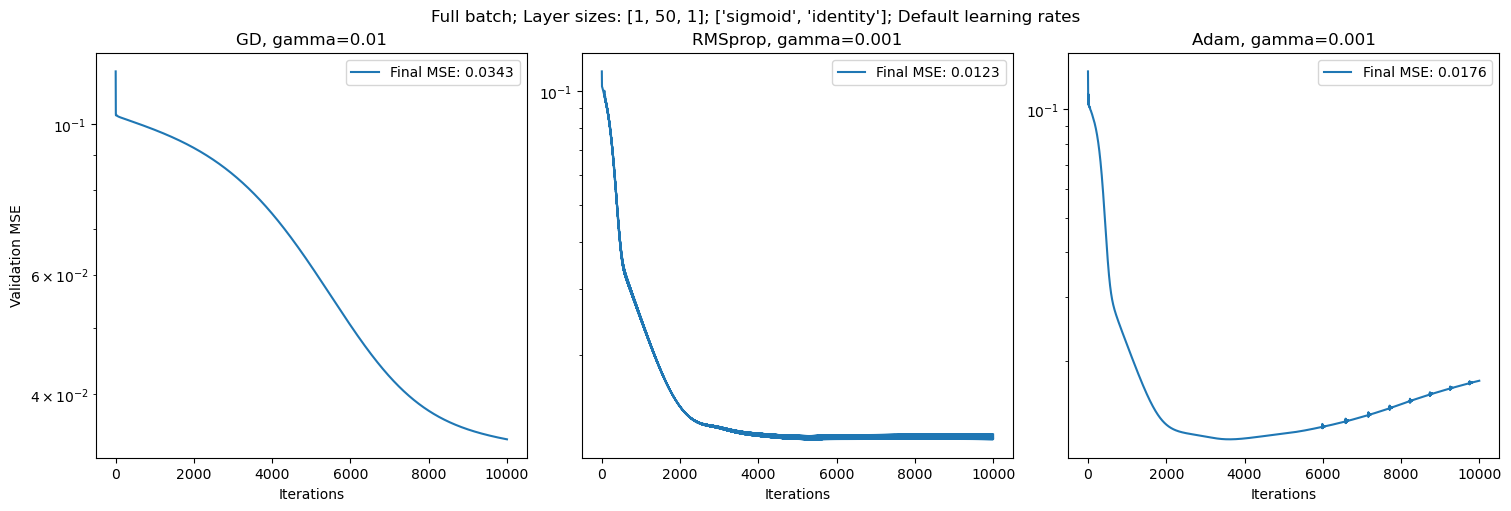

In [4]:
#initialize parameters for training the neural network
epochs = 10000
optimizer_class = [GD, RMSprop, Adam]

fig, ax = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for i in range(len(optimizer_class)):
    nn_model = NeuralNetwork(layer_sizes, activations)
    optimizer = optimizer_class[i]()
    error_history = train(nn_model, optimizer, X_train, y_train, epochs, X_val=X_val, y_val=y_val, max_mse=1.0)
    ax[i].plot(np.arange(0, epochs), error_history["val"], label=f"Final MSE: {error_history["val"][-1]:.4f}")
    ax[i].set_xlabel("Iterations")
    ax[i].set_yscale("log")
    ax[i].set_title(f"{optimizer.__class__.__name__}, gamma={optimizer.learning_rate}")
    ax[i].legend()

ax[0].set_ylabel("Validation MSE")
fig.suptitle(f"Full batch; Layer sizes: {layer_sizes}; {activations}; Default learning rates")
plt.show() 

In [13]:
batch_sizes = [4, 8, 16, 32, None]
learning_rates = np.geomspace(1e-3, 0.5, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        if len(error_history["val"]) != 0 and min(error_history["val"]) < 1.0:
            val_MSEs[k, g] = min(error_history["val"])
            best_epochs[k, g] = np.argmin(error_history["val"]) + 1 
        else: 
            val_MSEs[k, g] = np.nan
            best_epochs[k, g] = np.nan 

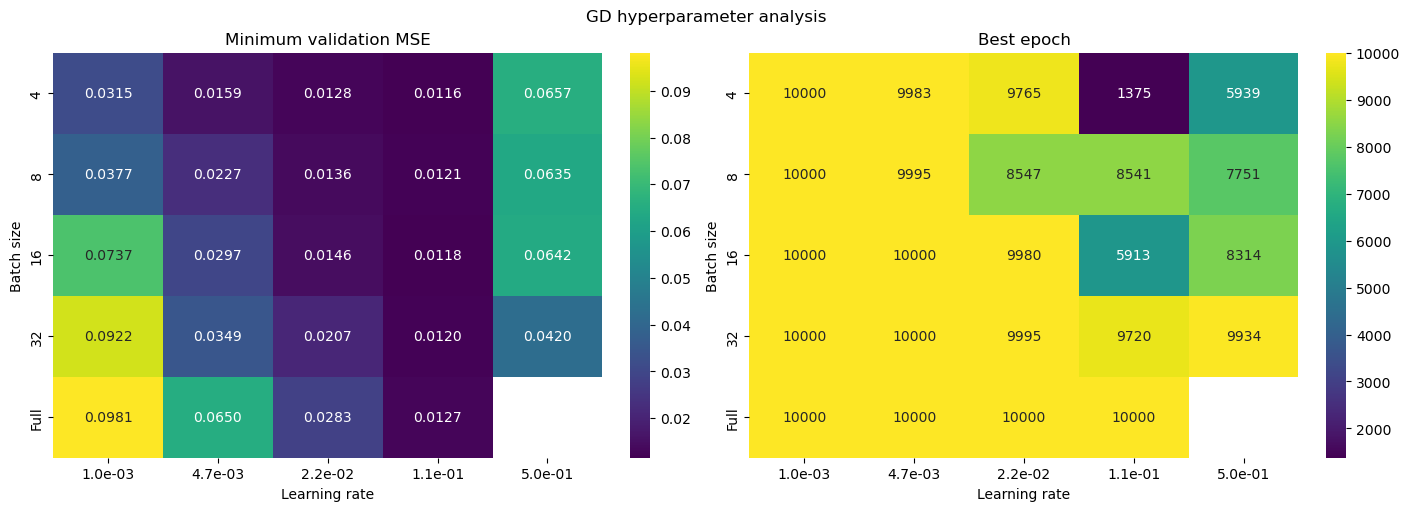

In [14]:
from plotting import plot_heatmap

fig, axs = plt.subplots(1, 2, figsize=(14, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[1]
)

fig.suptitle("GD hyperparameter analysis")
plt.show()

In [21]:
batch_sizes = [4, 8, 16, 32, None]
learning_rates = np.geomspace(0.11/4, 0.11*4, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        if len(error_history["val"]) != 0 and min(error_history["val"]) < 1.0:
            val_MSEs[k, g] = min(error_history["val"])
            best_epochs[k, g] = np.argmin(error_history["val"]) + 1 
        else: 
            val_MSEs[k, g] = np.nan
            best_epochs[k, g] = np.nan  

/Users/william/Desktop/UiO/ML/Project-2/Code/nn.py:16: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))


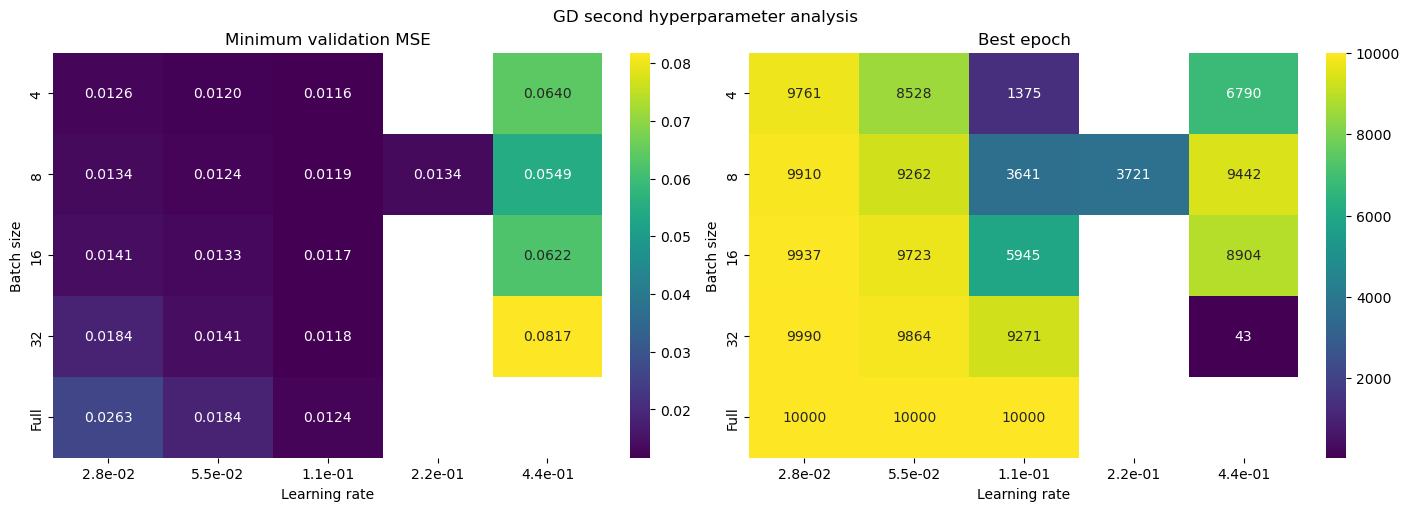

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

mask = val_MSEs > 0.1
val_MSEs[mask] = np.nan
best_epochs[mask] = np.nan

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[1]
)

fig.suptitle("GD second hyperparameter analysis")
plt.show()

Jeg tester batch size 4 med 1.1e-1 og 5.5e-2. 

In [23]:
batch_sizes = [1, 2, 4, 8]
learning_rates = np.geomspace(5.5e-2, 1.1e-1, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        if len(error_history["val"]) != 0 and min(error_history["val"]) < 1.0:
            val_MSEs[k, g] = min(error_history["val"])
            best_epochs[k, g] = np.argmin(error_history["val"]) + 1 
        else: 
            val_MSEs[k, g] = np.nan
            best_epochs[k, g] = np.nan

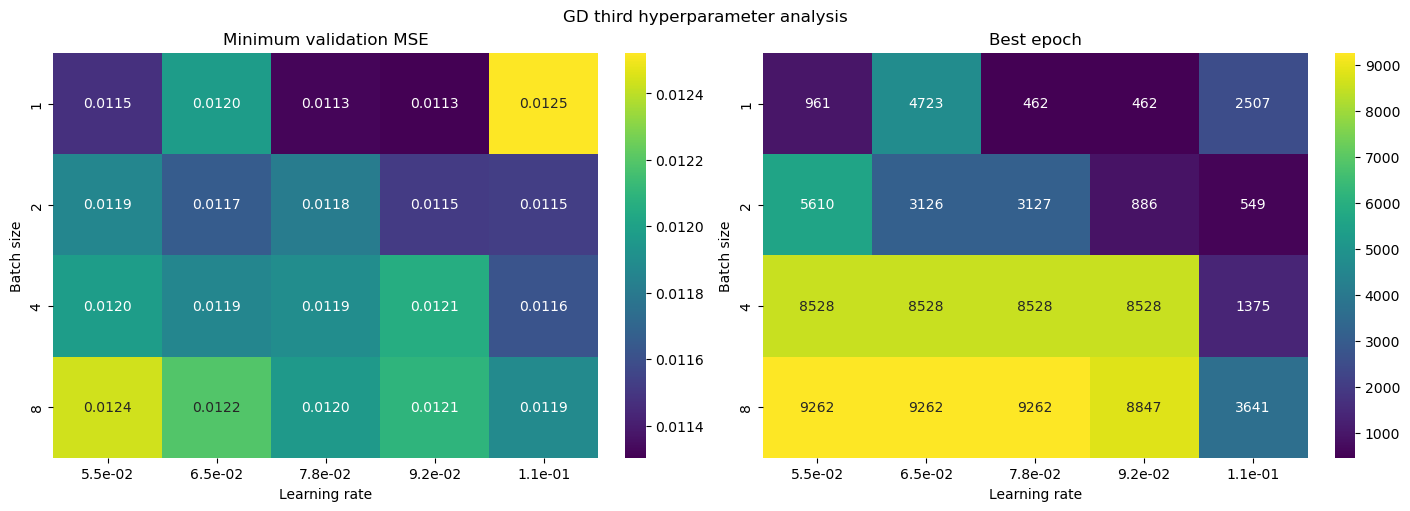

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

mask = val_MSEs > 0.03
val_MSEs[mask] = np.nan
best_epochs[mask] = np.nan

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[1]
)

fig.suptitle("GD third hyperparameter analysis")
plt.show()

Skriv at det er balanse mellom computational cost (lav batch size = høyere processing power. I analyse: As seen in figure above, reducing batch size generally reduces MSE, but at the cost of increasing processing power. It took 2 minutes and 39 seconds to run the last calculation, while the previous one with 4 being the smallest batch took 50 seconds(first run even included 5 Ms instead of 4)), validation MSE (want it to be small which means the network predicts the validation data well), and stability (if the MSE fluctuates strongly across epochs, using that specific learning rate, batch size and number of epochs BRA ELLER IKKE fordi den generaliser jo bra til validation MEN det er bare fordi vi velger lavest, det kan vi ikke med test. Vi later som at test data er noe som vi ikke vet y-verdiene til egentlig. Og jeg kan vel kanskje ikke bruke forskjellige seeds fordi jeg antar at jeg bare har fått de 100 datapunktene jeg har. Det var en utregning vi gjorde som viste at laveste mulige error (uten ren flaks) er sigma^2, altså 0.01. Hvordan skal jeg vurdere stability?). 

For this network, the number of weights and biases is not huge, meaning a small batch size is possible to use and we see that that is what generalises best to validation data. Først sjekk stabilitet med endret gamma: plot for M=4 og tre forskjellige gamma. Gjør det samme med M=2 og M=1 bare for å se at man får samme trend. SÅ: plot for samme gamma, M=4, 2, 1 for å se effekt av mindre batch size. Gjør for de to andre gammaene også for å se om samme effekt.

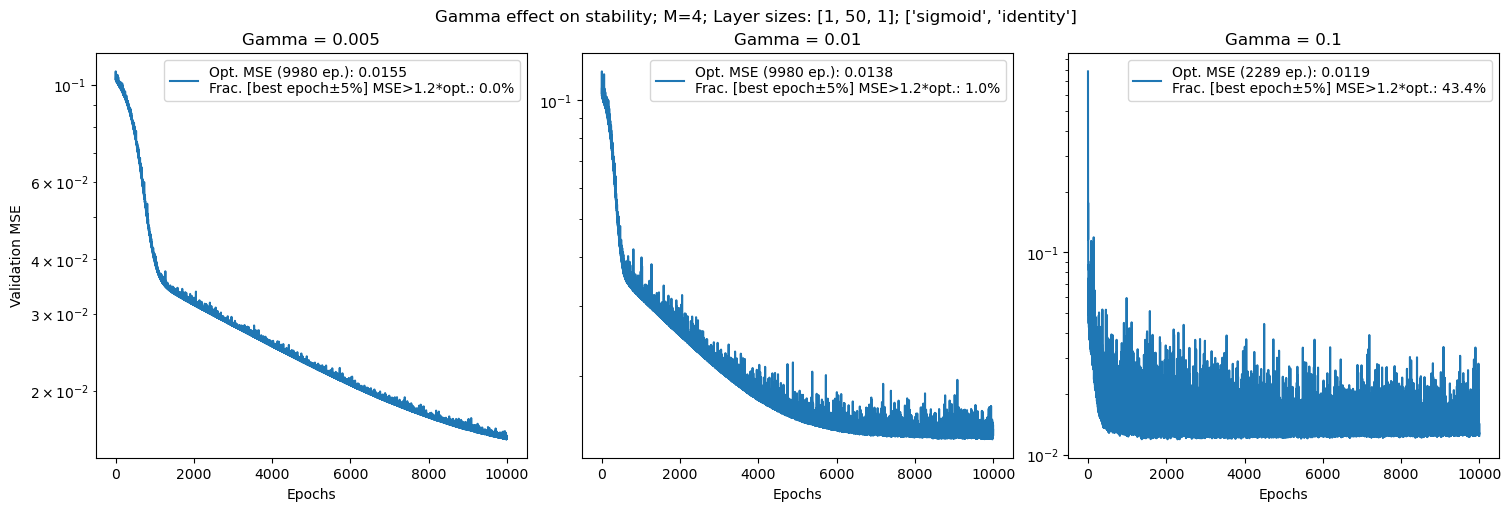

In [77]:
batch_size = 4
learning_rates = [5e-3, 1e-2, 1e-1]



fig, ax = plt.subplots(1, len(learning_rates), figsize=(5 * len(learning_rates), 5), constrained_layout=True)

for g in range(len(learning_rates)):    
    nn_model = NeuralNetwork(layer_sizes, activations)
    optimizer = GD(learning_rates[g])
    error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
    error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
    optimal = np.nanmin(error_history["val"])
    best_epoch = np.nanargmin(error_history["val"]) + 1
    early = best_epoch - int(best_epoch * 0.05)
    late = best_epoch + int(best_epoch * 0.05)
    window = np.array(error_history["val"][early:late])
    proportion = np.mean(window[~np.isnan(window)] > 1.2 * optimal)
    ax[g].plot(np.arange(0, epochs), error_history["val"], label=f"Opt. MSE ({best_epoch} ep.): {optimal:.4f}\nFrac. [best epoch±5%] MSE>1.2*opt.: {proportion*100:.1f}%")
    ax[g].set_xlabel("Epochs")
    ax[g].set_yscale("log")
    ax[g].set_title(f"Gamma = {optimizer.learning_rate}")
    ax[g].legend()

ax[0].set_ylabel("Validation MSE")
fig.suptitle(f"Gamma effect on stability; M=4; Layer sizes: {layer_sizes}; {activations}")
plt.show() 

Jeg har lyst på en mellomting mellom lav MSE og stabilitet. Denne figuren viser dette. Jeg trenger ikke at den er så stabil som første plot fordi det er viktig å få lav MSE også, men siste plot har høy andel av epochene rundt den beste med 20% høyere enn optimal value som betyr at den optimale løsningen funnet kanskje ikke generaliserer godt til test-dataset. Derfor er det best med en mellomting. Prøv 0.008, 0.01 og 0.02 og M=1? Det siste jeg testa var å jukse og sjekke hvordan de forskjellige modellene gjorde det på test-data og det virka som at de mer stabile kan være best. Prøv først gamma=0.01 og M=1, 4, 16 for å se batch size effect på stabilitet.

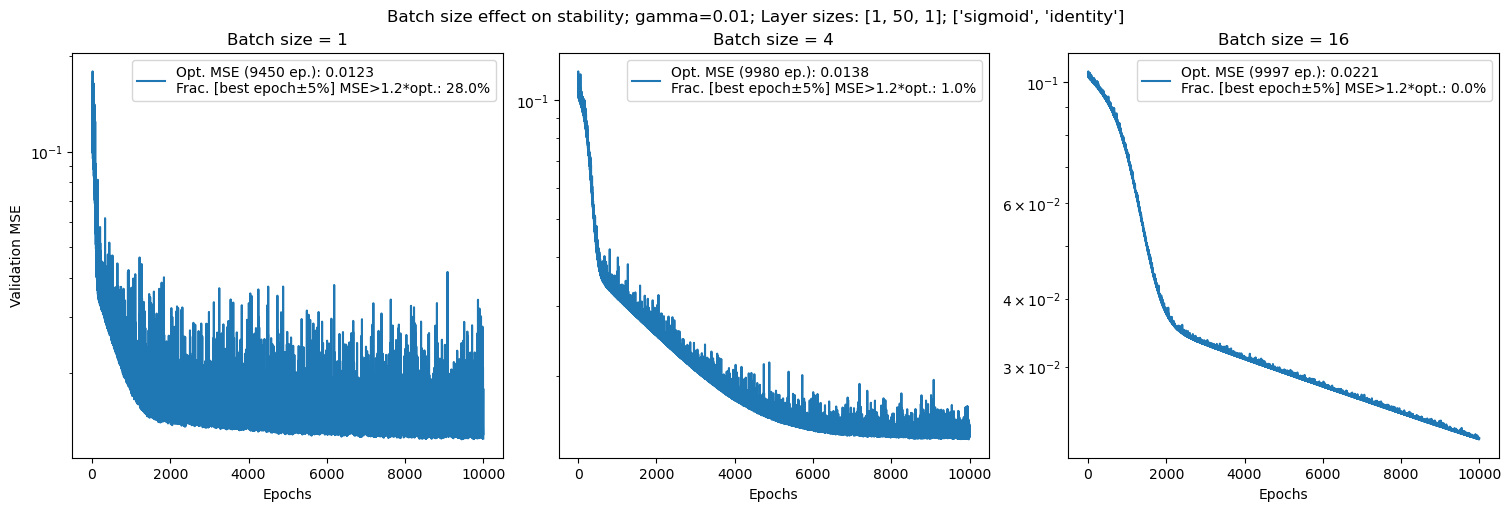

In [78]:
batch_sizes = [1, 4, 16]
learning_rate = 1e-2



fig, ax = plt.subplots(1, len(batch_sizes), figsize=(5 * len(batch_sizes), 5), constrained_layout=True)

for k in range(len(batch_sizes)):    
    nn_model = NeuralNetwork(layer_sizes, activations)
    optimizer = GD(learning_rate)
    error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_sizes[k], X_val=X_val, y_val=y_val, max_mse=1000.0)
    error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
    optimal = np.nanmin(error_history["val"])
    best_epoch = np.nanargmin(error_history["val"]) + 1
    early = best_epoch - int(best_epoch * 0.05)
    late = best_epoch + int(best_epoch * 0.05)
    window = np.array(error_history["val"][early:late])
    proportion = np.mean(window[~np.isnan(window)] > 1.2 * optimal)
    ax[k].plot(np.arange(0, epochs), error_history["val"], label=f"Opt. MSE ({best_epoch} ep.): {optimal:.4f}\nFrac. [best epoch±5%] MSE>1.2*opt.: {proportion*100:.1f}%")
    ax[k].set_xlabel("Epochs")
    ax[k].set_yscale("log")
    ax[k].set_title(f"Batch size = {batch_sizes[k]}")
    ax[k].legend()

ax[0].set_ylabel("Validation MSE")
fig.suptitle(f"Batch size effect on stability; gamma=0.01; Layer sizes: {layer_sizes}; {activations}")
plt.show()

This figure shows that smaller batch size for SGD causes more fluctuations in the validation MSE scores, suggesting that the model might be overfitted to the training data, thereby causing worse generalisation to unseen data. Since the neural network used here is relatively simple, the processing power needed to analyse low batch sizes is not too large, making us able to analyse the effects of low batch sizes and choosing whichever combination of batch size and learning rate that shows a good balance between stability and low MSE. Plot a grid plot showing validation MSE and fraction for some good candidates. M=2,4,8. Prøv 0.008, 0.01, 0.02.

In [91]:
epochs = 15000
batch_sizes = [2, 4, 8]
learning_rates = [8e-3, 1e-2, 2e-2]

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
fractions = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
        optimal = np.nanmin(error_history["val"])
        best_epoch = np.nanargmin(error_history["val"]) + 1

        radius = max(1, int(best_epoch * 0.05))
        early = max(0, best_epoch - 1 - radius)
        late = min(len(error_history["val"]), best_epoch + radius)

        window = np.array(error_history["val"][early:late])
        proportion = np.mean(window[~np.isnan(window)] > 0.015)

        val_MSEs[k, g] = optimal
        fractions[k, g] = proportion
        best_epochs[k, g] = best_epoch

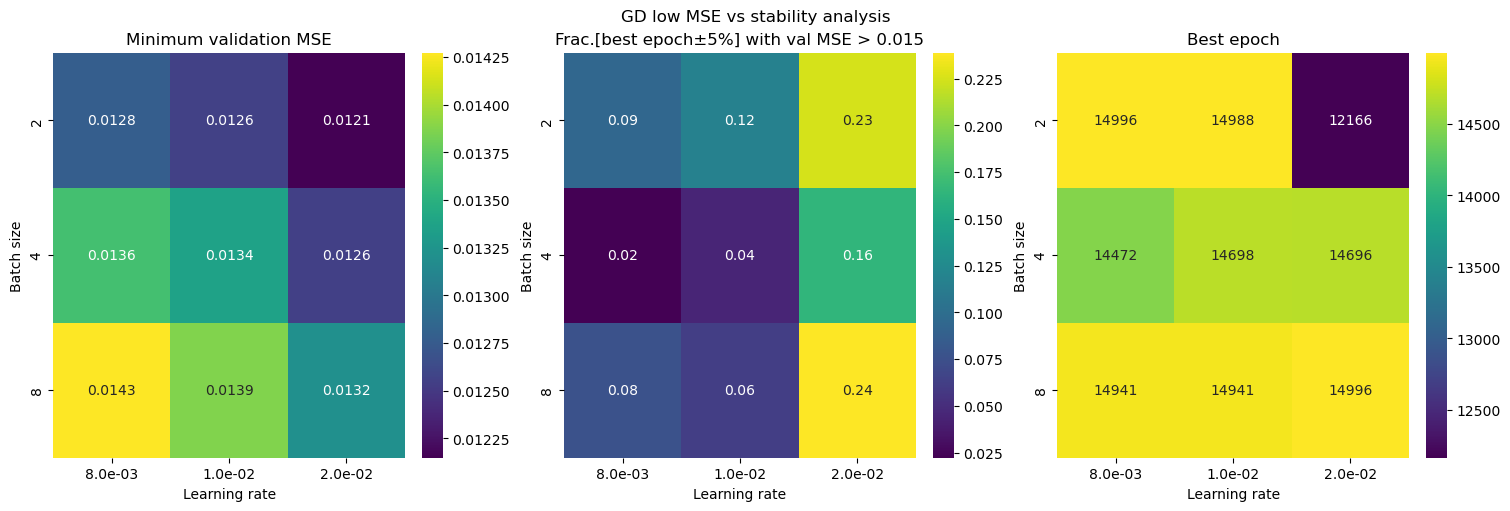

In [92]:
fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    fractions,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Frac.[best epoch±5%] with val MSE > 0.015",
    fmt=".2f",
    ax=axs[1]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[2]
)

fig.suptitle("GD low MSE vs stability analysis")
plt.show()

I decided to use 8e-3 and M=4. When trying the different models on the test data (måtte teste fordi jeg vet jo ingenting om hvilken stabilitet som egentlig er nødvendig), this turned out to be a worse choice than going for less stability and lower minimum val MSE (see below). 

In [95]:
batch_size = 4
gamma = 8e-3
epochs = 14472
nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print(f"Test MSE: {test_error}")
print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

Test MSE: 0.020800201562992088
Val MSE: 0.013638662194180052


In [94]:
batch_size = 2
gamma = 2e-2
epochs = 12166
nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print(f"Test MSE: {test_error}")
print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

Test MSE: 0.013507965519556303
Val MSE: 0.01214863143678244


In [93]:
batch_size = 4
gamma = 2e-2
epochs = 14696
nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print(f"Test MSE: {test_error}")
print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

Test MSE: 0.0153111676870091
Val MSE: 0.012554032143908642


In [96]:
batch_size = 2
gamma = 1e-2
epochs = 14988
nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print(f"Test MSE: {test_error}")
print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

Test MSE: 0.01576011164705036
Val MSE: 0.01255678176496273


Konklusjon: trenger ikke være sånn fryktelig stabil hvis den har klart å oppnå lav MSE på val data. Try again with 4, 2, 1 and gamma=1e-2, 2e-2, 4e-2.

In [97]:
epochs = 15000
batch_sizes = [1, 2, 4]
learning_rates = [1e-2, 2e-2, 4e-2]

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
fractions = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
        optimal = np.nanmin(error_history["val"])
        best_epoch = np.nanargmin(error_history["val"]) + 1

        radius = max(1, int(best_epoch * 0.05))
        early = max(0, best_epoch - 1 - radius)
        late = min(len(error_history["val"]), best_epoch + radius)

        window = np.array(error_history["val"][early:late])
        proportion = np.mean(window[~np.isnan(window)] > 0.015)

        val_MSEs[k, g] = optimal
        fractions[k, g] = proportion
        best_epochs[k, g] = best_epoch

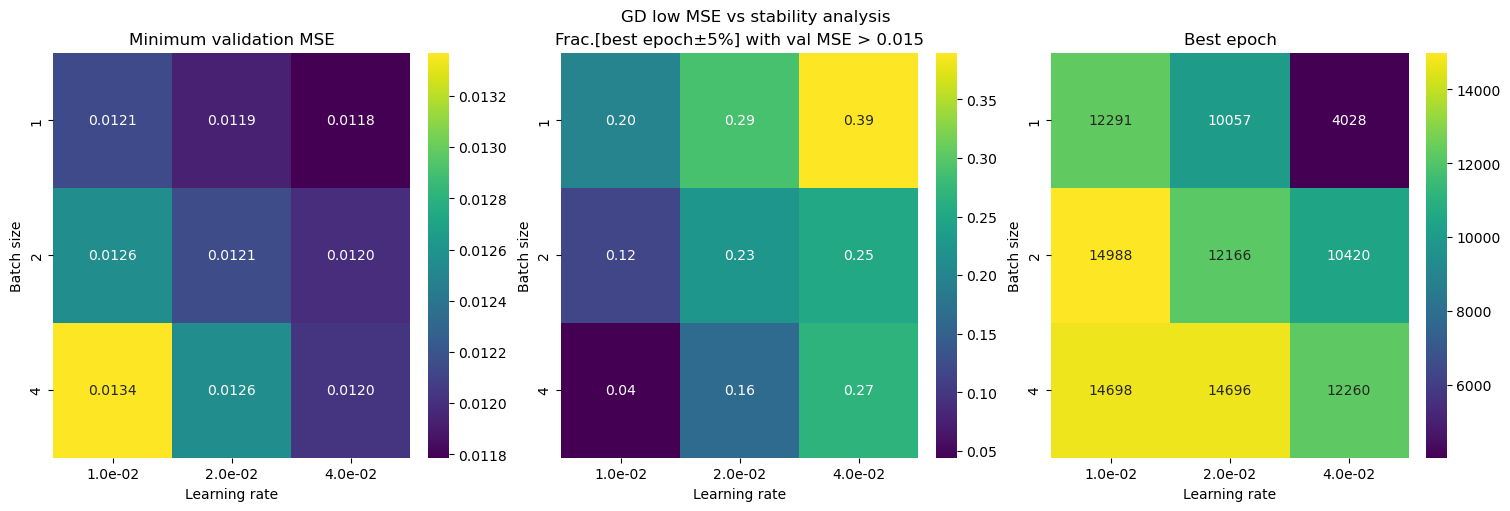

In [98]:
fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    fractions,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Frac.[best epoch±5%] with val MSE > 0.015",
    fmt=".2f",
    ax=axs[1]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[2]
)

fig.suptitle("GD low MSE vs stability analysis")
plt.show()

In [ ]:
trials = [(4, 1e-2, 14698), (2, 2e-2, 12166), (1, 4e-2, 4028), ]

for batch_size, gamma, epochs in trials:    
    nn_model = NeuralNetwork(layer_sizes, activations)
    optimizer = GD(gamma)
    error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
    test_error = nn_model.cost(X_test, y_test)
    print(f"M={batch_size}, gamma={gamma}:")
    print(f"Test MSE: {test_error}")
    #print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

M=4, gamma=0.01:
Test MSE: 0.01979712007288415
Val MSE: 0.013367936182630625
M=2, gamma=0.02:
Test MSE: 0.013507965519556303
Val MSE: 0.01214863143678244
M=1, gamma=0.04:
Test MSE: 0.012873932554370365
Val MSE: 0.011787388971014987


Nå har jeg endelig kommet frem til at fuck stabilitet tror jeg. Når jeg testa igår med forskjellige seeds så gjorde jeg jo feil. når den er trent på andre dataer så vil det jo bli en dårlig modell når man bruker samme epochs etc. men veldig ustabil må vel være dårlig?? test batch size 1, 2, 4 og learning rate 7.8e-2 til 1.1e-1 med geomspace 5 stykker

In [105]:
epochs = 10000
batch_sizes = [1, 2, 4]
learning_rates = np.geomspace(5.5e-2, 1.1e-1, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
fractions = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
        optimal = np.nanmin(error_history["val"])
        best_epoch = np.nanargmin(error_history["val"]) + 1

        radius = max(1, int(best_epoch * 0.05))
        early = max(0, best_epoch - 1 - radius)
        late = min(len(error_history["val"]), best_epoch + radius)

        window = np.array(error_history["val"][early:late])
        proportion = np.mean(window[~np.isnan(window)] > 0.015)

        val_MSEs[k, g] = optimal
        fractions[k, g] = proportion
        best_epochs[k, g] = best_epoch

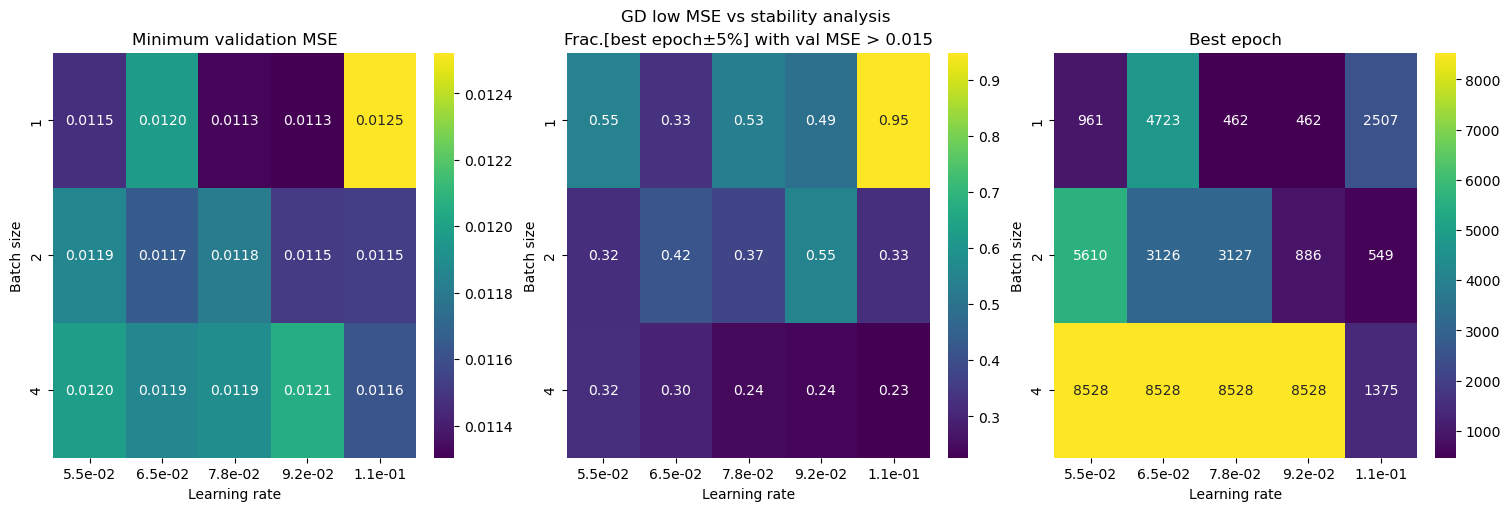

In [106]:
fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.1e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".4f",
    ax=axs[0]
)

plot_heatmap(
    fractions,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Frac.[best epoch±5%] with val MSE > 0.015",
    fmt=".2f",
    ax=axs[1]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[2]
)

fig.suptitle("GD low MSE vs stability analysis")
plt.show()

In [107]:
batch_sizes = [1, 2]
learning_rates = np.geomspace(7.5e-2, 1e-1, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
fractions = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = GD(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))
        optimal = np.nanmin(error_history["val"])
        best_epoch = np.nanargmin(error_history["val"]) + 1

        radius = max(1, int(best_epoch * 0.05))
        early = max(0, best_epoch - 1 - radius)
        late = min(len(error_history["val"]), best_epoch + radius)

        window = np.array(error_history["val"][early:late])
        proportion = np.mean(window[~np.isnan(window)] > 0.015)

        val_MSEs[k, g] = optimal
        fractions[k, g] = proportion
        best_epochs[k, g] = best_epoch

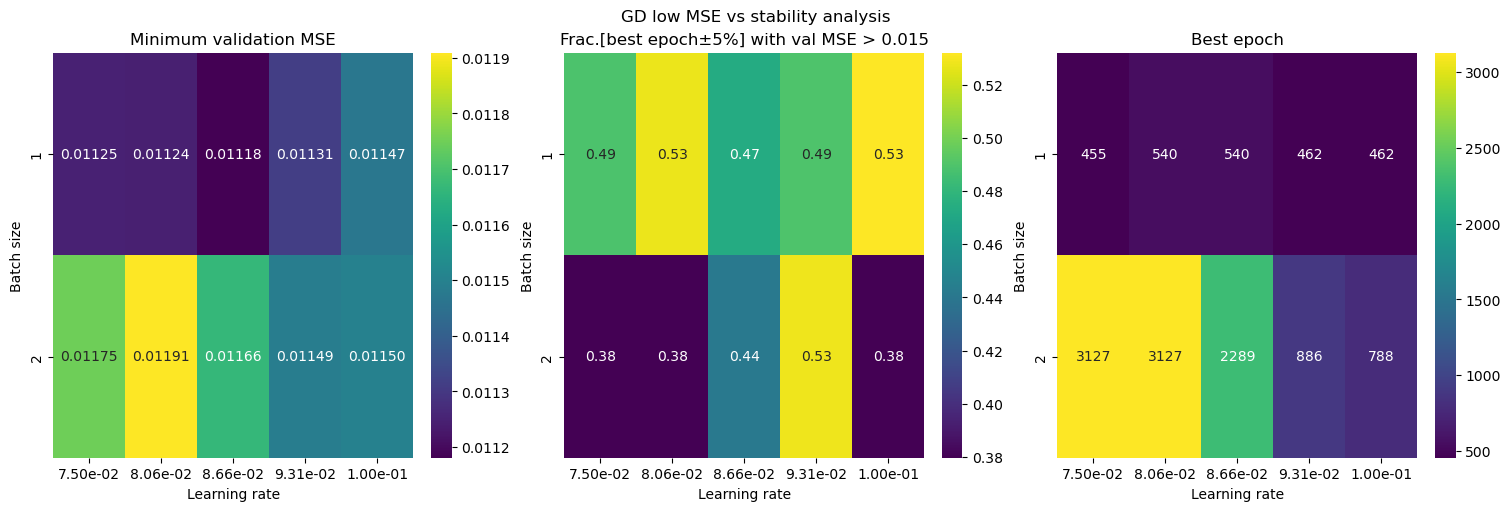

In [111]:
fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.2e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".5f",
    ax=axs[0]
)

plot_heatmap(
    fractions,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Frac.[best epoch±5%] with val MSE > 0.015",
    fmt=".2f",
    ax=axs[1]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[2]
)

fig.suptitle("GD low MSE vs stability analysis")
plt.show()

In [109]:
trials = [(1, 7.5e-2, 455), (1, 8.1e-2, 540), (1, 8.7e-2, 540)]

for batch_size, gamma, epochs in trials:    
    nn_model = NeuralNetwork(layer_sizes, activations)
    optimizer = GD(gamma)
    error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
    test_error = nn_model.cost(X_test, y_test)
    print(f"M={batch_size}, gamma={gamma}:")
    print(f"Test MSE: {test_error}")
    print(f"Val MSE: {error_history["val"][-1]}") #Bare for å sjekke om samme som plot

M=1, gamma=0.075:
Test MSE: 0.01383782678641334
Val MSE: 0.011247736290056045
M=1, gamma=0.081:
Test MSE: 0.012490380679761656
Val MSE: 0.011230304200595023
M=1, gamma=0.087:
Test MSE: 0.01288457817104558
Val MSE: 0.011184599215551505


Viser seg at det virker uviktig med stabilitet. Velg den som har lavest val MSE som er M=1 og gamma=8.7e-2. Lat som at jeg ikke prøvde på test først?

Denne modellen gir følgende test MSE:

In [149]:
batch_size = 1
gamma = 8.66e-2
epochs = 540

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT PLAIN GD:")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT PLAIN GD:
M=1, gamma=0.0866, epochs=540:
Test MSE: 0.01287


Gjør de neste (RMSProp og Adam). Eneste jeg ser etter er lav val MSE. 

In [159]:
#### FOR RMSProp ####

batch_sizes = [1, 4, 16, None]
learning_rates = np.geomspace(1e-3, 1, 5)

val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
fractions = np.empty((len(batch_sizes), len(learning_rates)))
best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
for k in range(len(batch_sizes)):
    batch_size=batch_sizes[k]
    for g in range(len(learning_rates)):
        gamma = learning_rates[g]
        optimizer = RMSprop(gamma)
        
        nn_model = NeuralNetwork(layer_sizes, activations)
        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
        error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))

        if np.all(np.isnan(error_history["val"])):
            val_MSEs[k, g] = np.nan
            fractions[k, g] = np.nan
            best_epochs[k, g] = np.nan
            continue
        
        optimal = np.nanmin(error_history["val"])
        best_epoch = np.nanargmin(error_history["val"]) + 1

        radius = max(1, int(best_epoch * 0.05))
        early = max(0, best_epoch - 1 - radius)
        late = min(len(error_history["val"]), best_epoch + radius)

        window = np.array(error_history["val"][early:late])
        proportion = np.mean(window[~np.isnan(window)] > 0.015)

        val_MSEs[k, g] = optimal
        fractions[k, g] = proportion
        best_epochs[k, g] = best_epoch

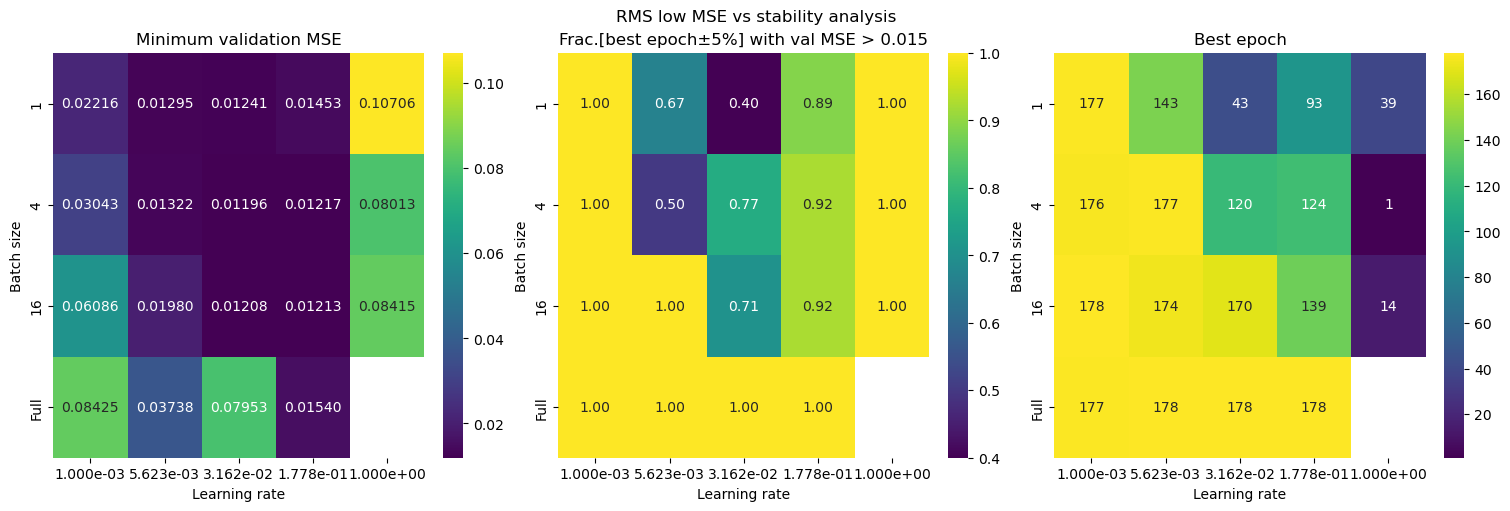

In [160]:
fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
lr_labels = [f"{lr:.3e}" for lr in learning_rates]

plot_heatmap(
    val_MSEs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Minimum validation MSE",
    fmt=".5f",
    ax=axs[0]
)

plot_heatmap(
    fractions,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Frac.[best epoch±5%] with val MSE > 0.015",
    fmt=".2f",
    ax=axs[1]
)

plot_heatmap(
    best_epochs,
    x_labels=lr_labels,
    y_labels=batch_labels,
    x_name="Learning rate",
    y_name="Batch size",
    title="Best epoch",
    fmt=".0f",
    ax=axs[2]
)

fig.suptitle("RMS low MSE vs stability analysis")
plt.show()

In [ ]:
def RMS_hyperpar_analysis(batch_sizes, learning_rates):
    val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
    fractions = np.empty((len(batch_sizes), len(learning_rates)))
    best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
    for k in range(len(batch_sizes)):
        batch_size=batch_sizes[k]
        for g in range(len(learning_rates)):
            gamma = learning_rates[g]
            optimizer = RMSprop(gamma)
        
            nn_model = NeuralNetwork(layer_sizes, activations)
            error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
            error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))

            if np.all(np.isnan(error_history["val"])):
                val_MSEs[k, g] = np.nan
                fractions[k, g] = np.nan
                best_epochs[k, g] = np.nan
                continue
        
            optimal = np.nanmin(error_history["val"])
            best_epoch = np.nanargmin(error_history["val"]) + 1

            radius = max(1, int(best_epoch * 0.05))
            early = max(0, best_epoch - 1 - radius)
            late = min(len(error_history["val"]), best_epoch + radius)

            window = np.array(error_history["val"][early:late])
            proportion = np.mean(window[~np.isnan(window)] > 0.015)

            val_MSEs[k, g] = optimal
            fractions[k, g] = proportion
            best_epochs[k, g] = best_epoch

    return val_MSEs, fractions, best_epochs

batch_sizes = [1, 4, 16]
learning_rates = np.geomspace(5e-3, 1, 7)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)

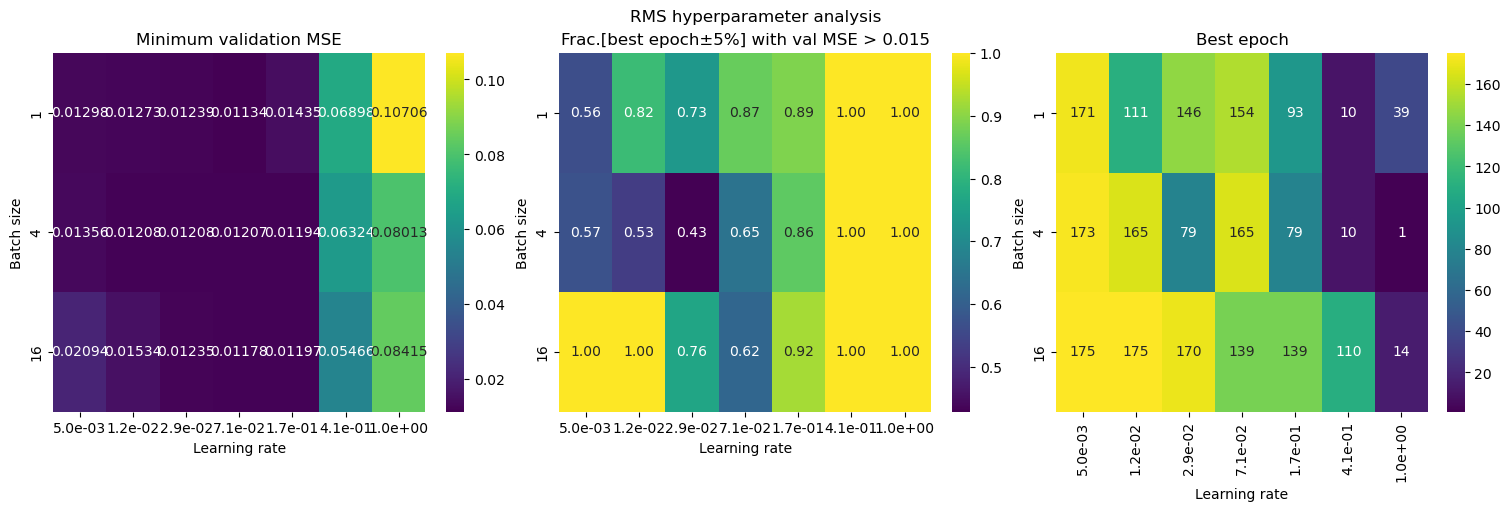

In [162]:
def hyperpar_plot(val_MSEs, fractions, best_epochs):
    fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

    batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
    lr_labels = [f"{lr:.1e}" for lr in learning_rates]

    plot_heatmap(
        val_MSEs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Minimum validation MSE",
        fmt=".5f",
        ax=axs[0]
    )

    plot_heatmap(
        fractions,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Frac.[best epoch±5%] with val MSE > 0.015",
        fmt=".2f",
        ax=axs[1]
    )

    plot_heatmap(
        best_epochs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Best epoch",
        fmt=".0f",
        ax=axs[2]
    )

    fig.suptitle("RMS hyperparameter analysis")
    plt.show()

hyperpar_plot(val_MSEs, fractions, best_epochs)

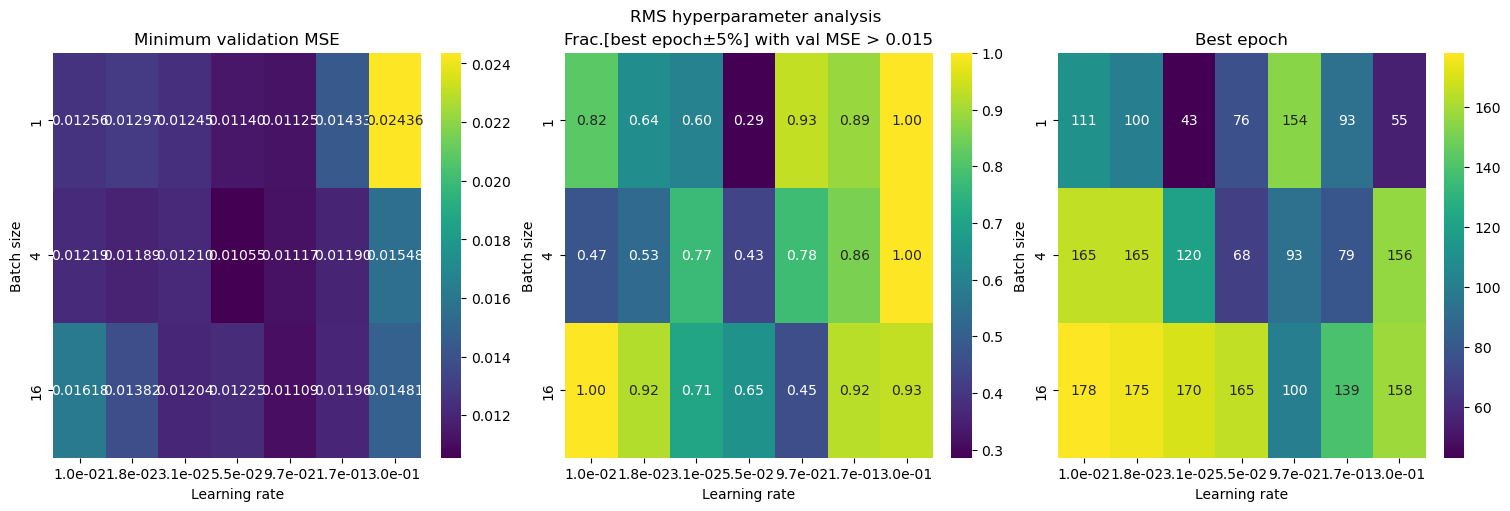

In [163]:
batch_sizes = [1, 4, 16]
learning_rates = np.geomspace(1e-2, 3e-1, 7)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

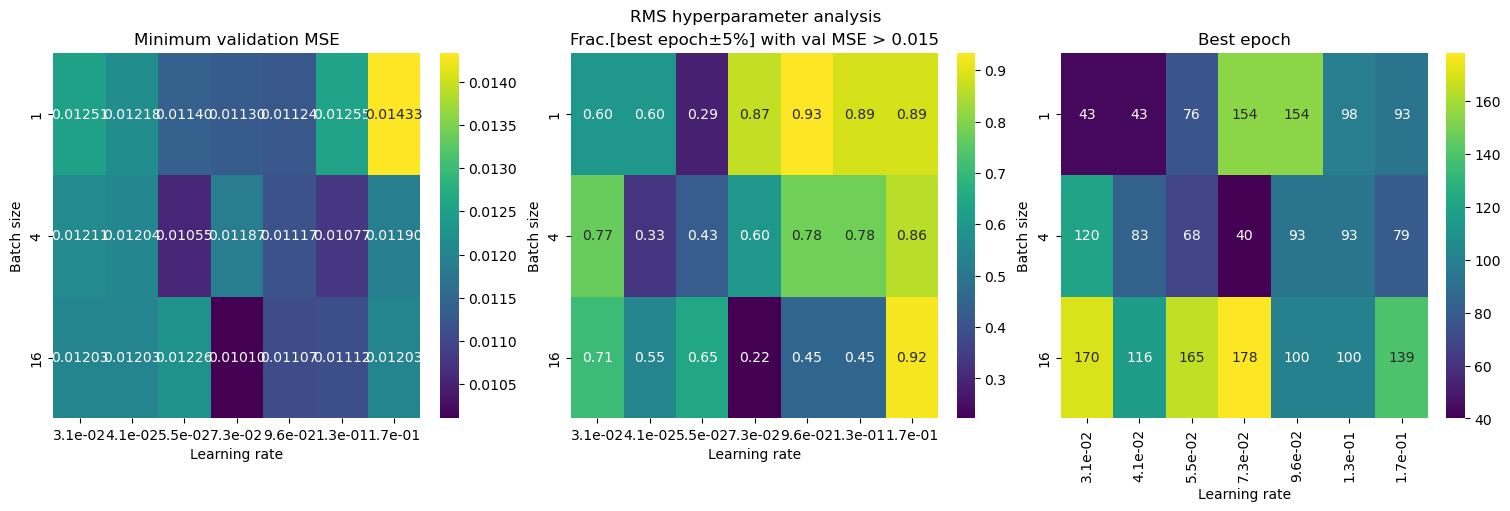

In [164]:
batch_sizes = [1, 4, 16]
learning_rates = np.geomspace(3.1e-2, 1.7e-1, 7)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

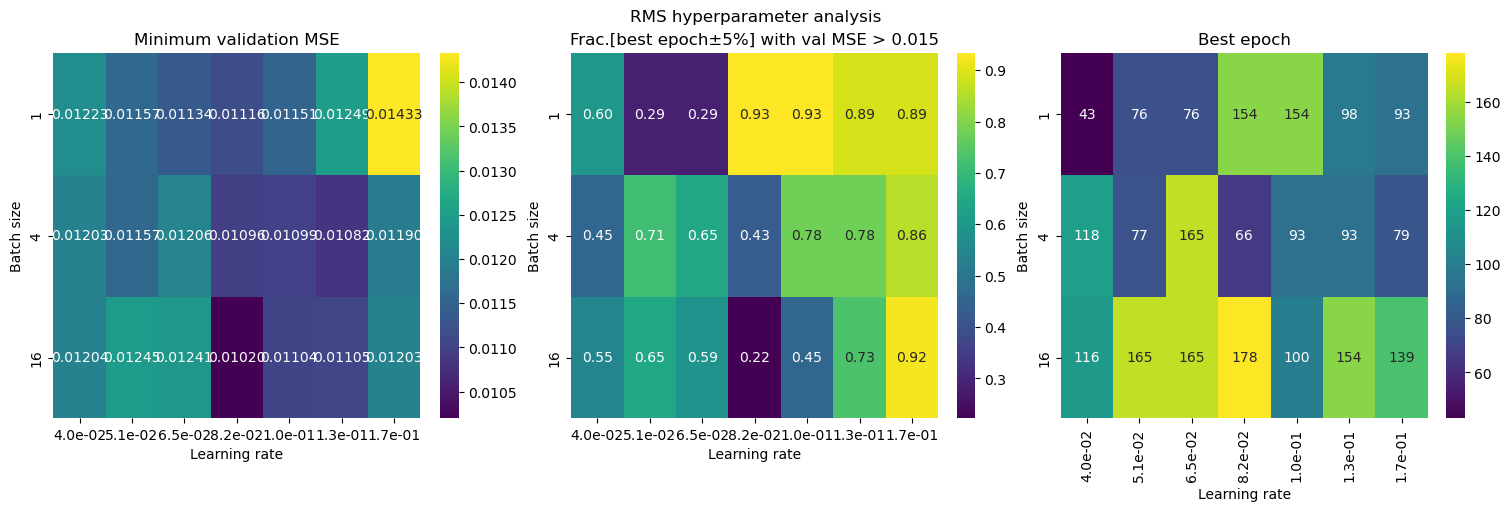

In [165]:
batch_sizes = [1, 4, 16]
learning_rates = np.geomspace(4e-2, 1.7e-1, 7)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

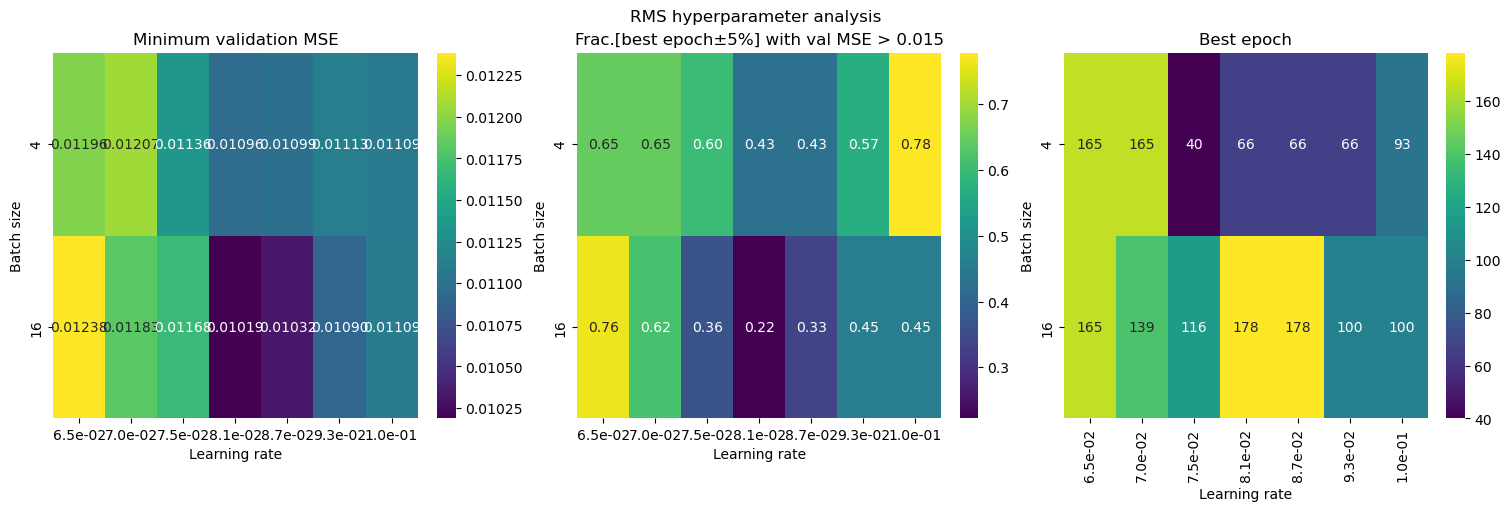

In [166]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(6.5e-2, 1e-1, 7)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

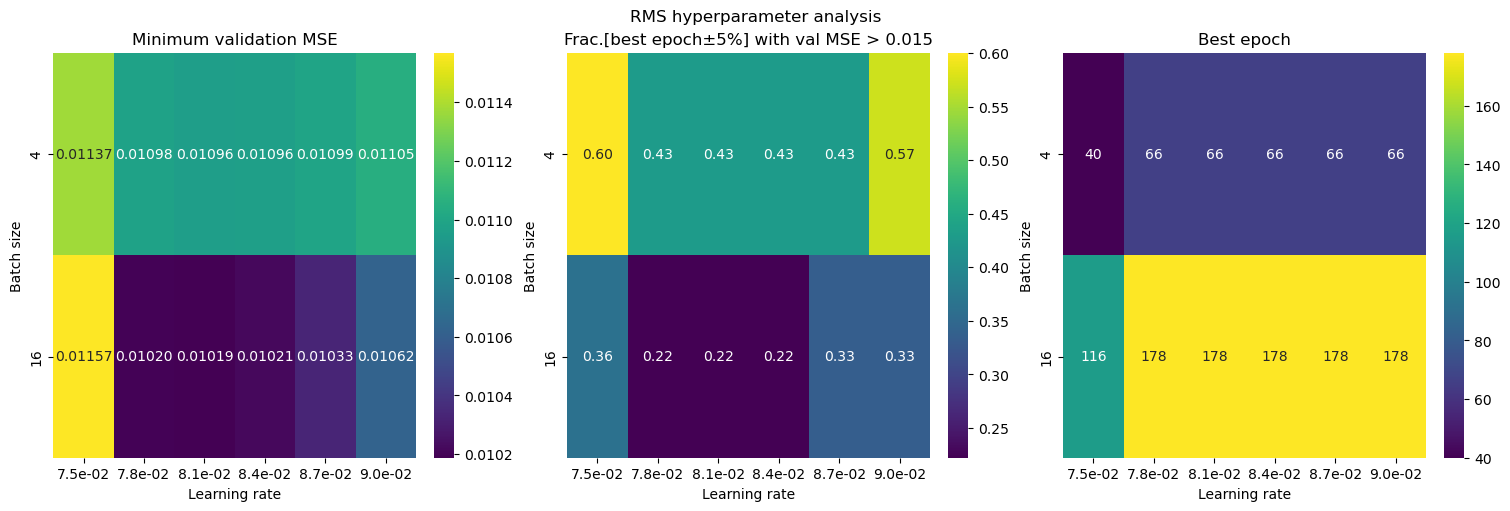

In [167]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(7.5e-2, 9e-2, 6)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

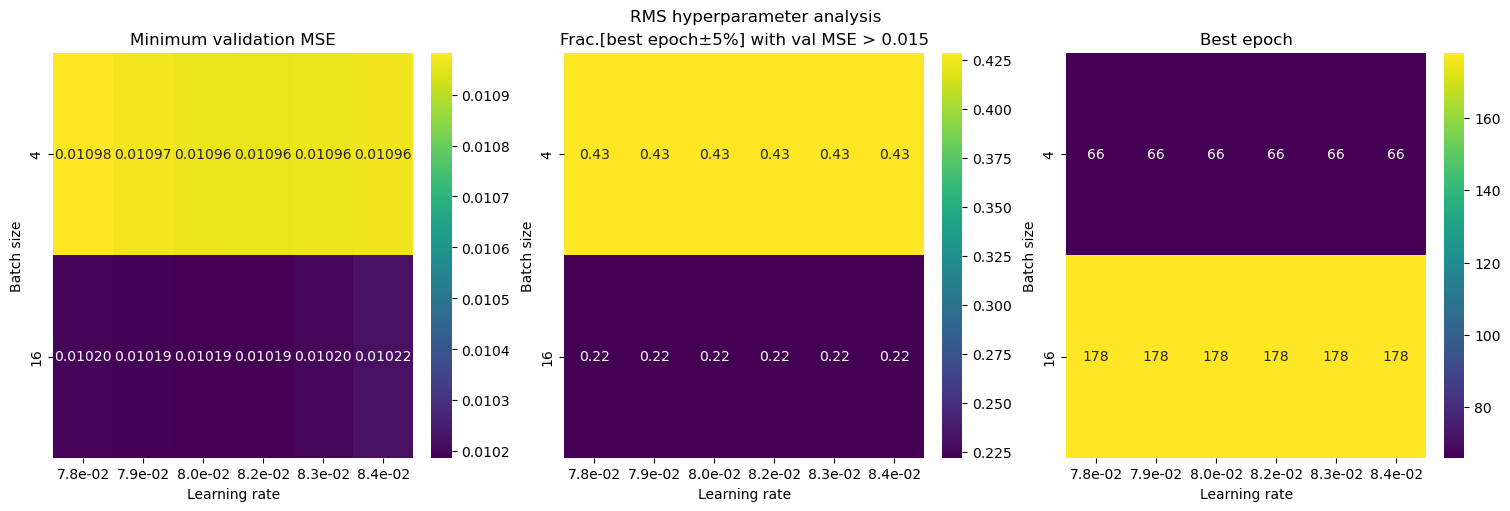

In [168]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(7.8e-2, 8.4e-2, 6)
val_MSEs, fractions, best_epochs = RMS_hyperpar_analysis(batch_sizes, learning_rates)
hyperpar_plot(val_MSEs, fractions, best_epochs)

I choose M=16, gamma=8.2e-2, epochs = 178.

In [169]:
batch_size = 16
gamma = 8.2e-2
epochs = 178

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = RMSprop(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT RMSProp:")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT RMSProp:
M=16, gamma=0.082, epochs=178:
Test MSE: 0.01278


Litt bedre enn plain GD. Gjør for Adam.

In [ ]:
def hyperpar_analysis(optimizer_class, batch_sizes, learning_rates):
    val_MSEs = np.empty((len(batch_sizes), len(learning_rates)))
    fractions = np.empty((len(batch_sizes), len(learning_rates)))
    best_epochs = np.empty((len(batch_sizes), len(learning_rates)))
    for k in range(len(batch_sizes)):
        batch_size=batch_sizes[k]
        for g in range(len(learning_rates)):
            gamma = learning_rates[g]
            optimizer = optimizer_class(gamma)
        
            nn_model = NeuralNetwork(layer_sizes, activations)
            error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
            error_history["val"].extend([np.nan] * (epochs - len(error_history["val"])))

            if np.all(np.isnan(error_history["val"])):
                val_MSEs[k, g] = np.nan
                fractions[k, g] = np.nan
                best_epochs[k, g] = np.nan
                continue
        
            optimal = np.nanmin(error_history["val"])
            best_epoch = np.nanargmin(error_history["val"]) + 1

            radius = max(1, int(best_epoch * 0.05))
            early = max(0, best_epoch - 1 - radius)
            late = min(len(error_history["val"]), best_epoch + radius)

            window = np.array(error_history["val"][early:late])
            proportion = np.mean(window[~np.isnan(window)] > 0.015)

            val_MSEs[k, g] = optimal
            fractions[k, g] = proportion
            best_epochs[k, g] = best_epoch

    return val_MSEs, fractions, best_epochs

def hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs):
    fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

    batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
    lr_labels = [f"{lr:.2e}" for lr in learning_rates]

    plot_heatmap(
        val_MSEs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Minimum validation MSE",
        fmt=".5f",
        ax=axs[0]
    )

    plot_heatmap(
        fractions,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Frac.[best epoch±5%] with val MSE > 0.015",
        fmt=".2f",
        ax=axs[1]
    )

    plot_heatmap(
        best_epochs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Best epoch",
        fmt=".0f",
        ax=axs[2]
    )

    fig.suptitle(f"{optimizer_class.__name__} hyperparameter analysis.")
    plt.show()

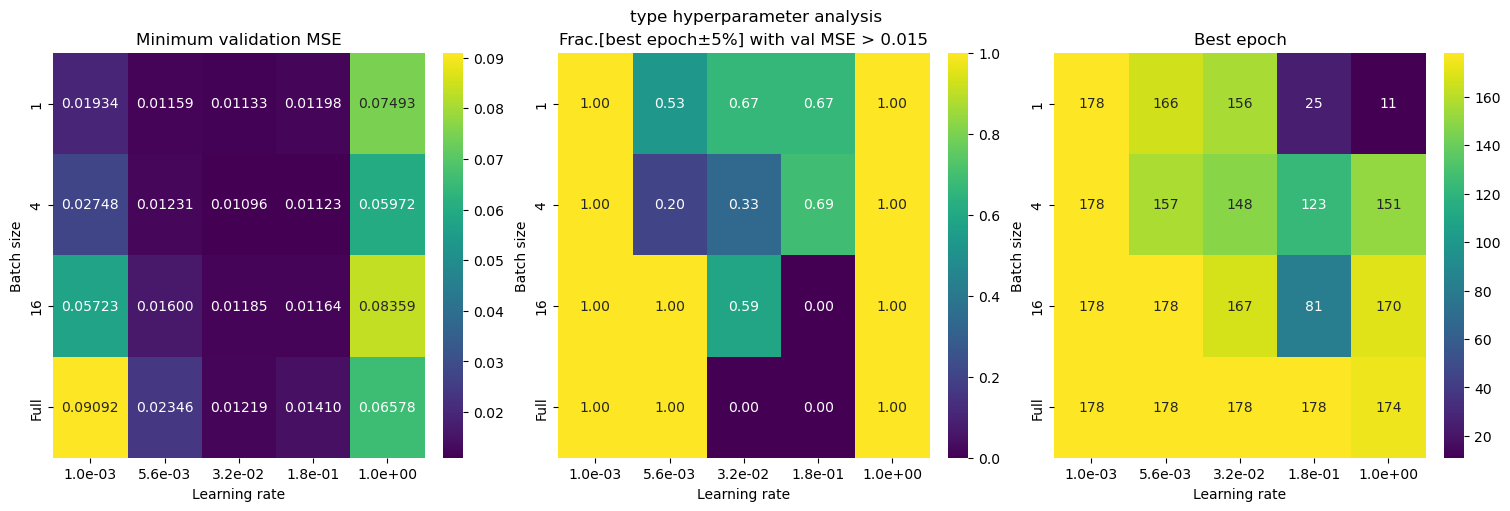

In [173]:
optimizer_class = Adam
batch_sizes = [1, 4, 16, None]
learning_rates = np.geomspace(1e-3, 1, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

Husk å skrive hva jeg bruker som stopping condition fordi det er det som gjør at denne analysen går så fort. For plain GD så tok det lang tid å komme ned og er derfor mye tyngre computationally og bør ikke brukes på mer kompliserte nettverk.

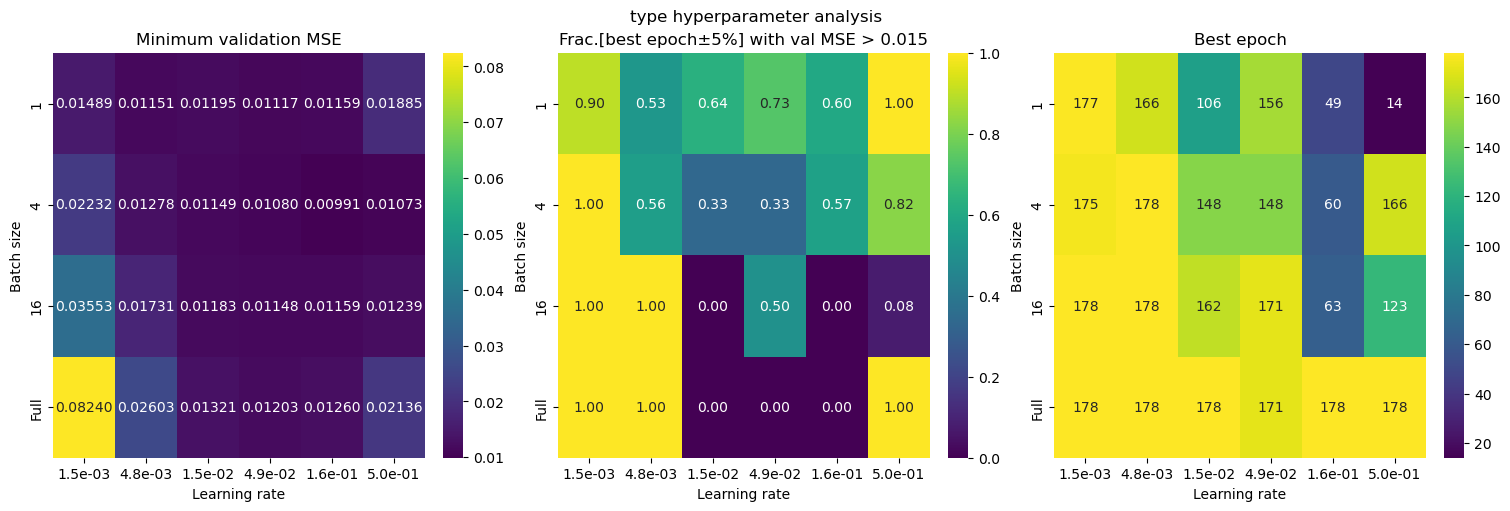

In [174]:
batch_sizes = [1, 4, 16, None]
learning_rates = np.geomspace(1.5e-3, 5e-1, 6)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

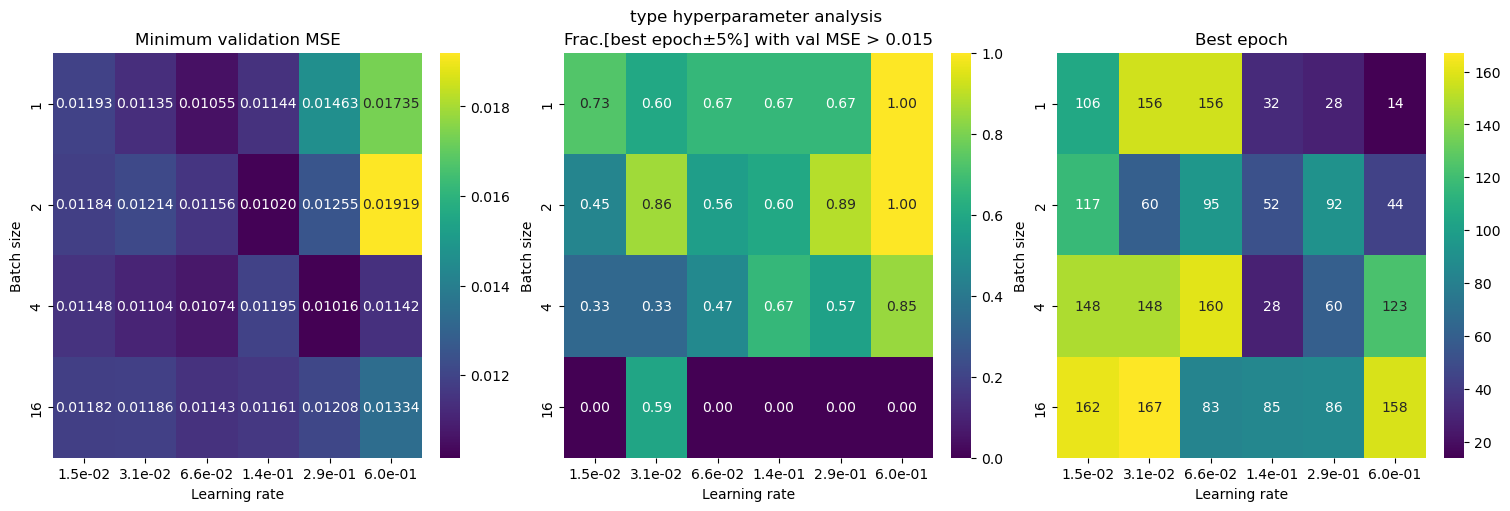

In [175]:
batch_sizes = [1, 2, 4, 16]
learning_rates = np.geomspace(1.5e-2, 6e-1, 6)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

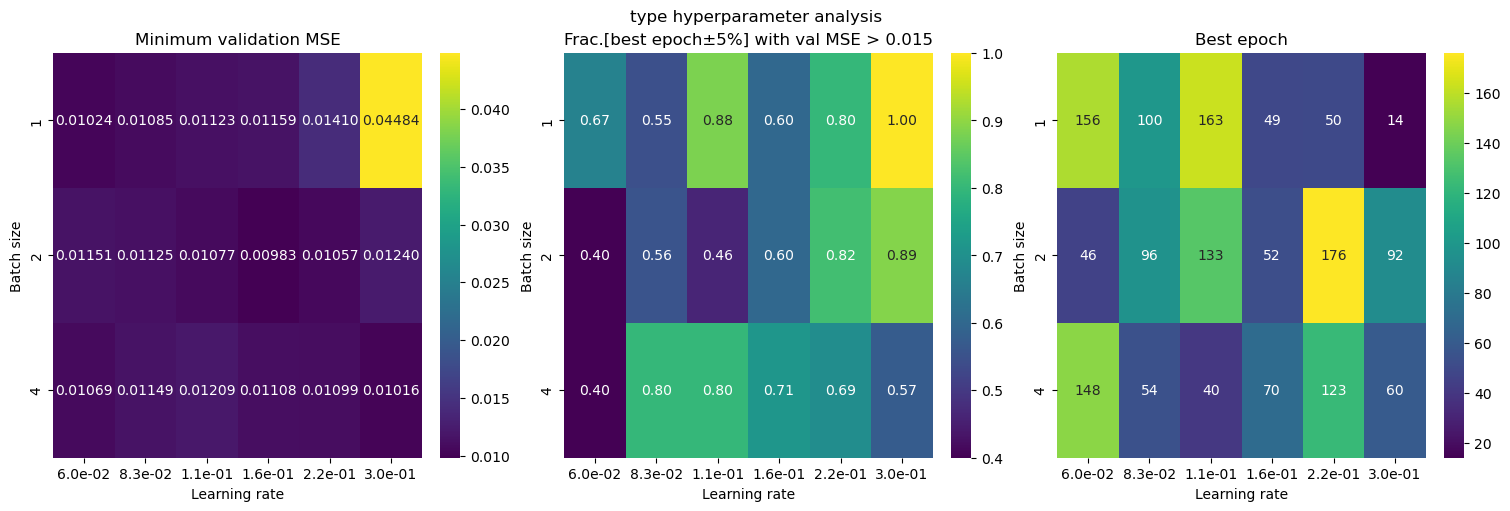

In [176]:
batch_sizes = [1, 2, 4]
learning_rates = np.geomspace(6e-2, 3e-1, 6)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

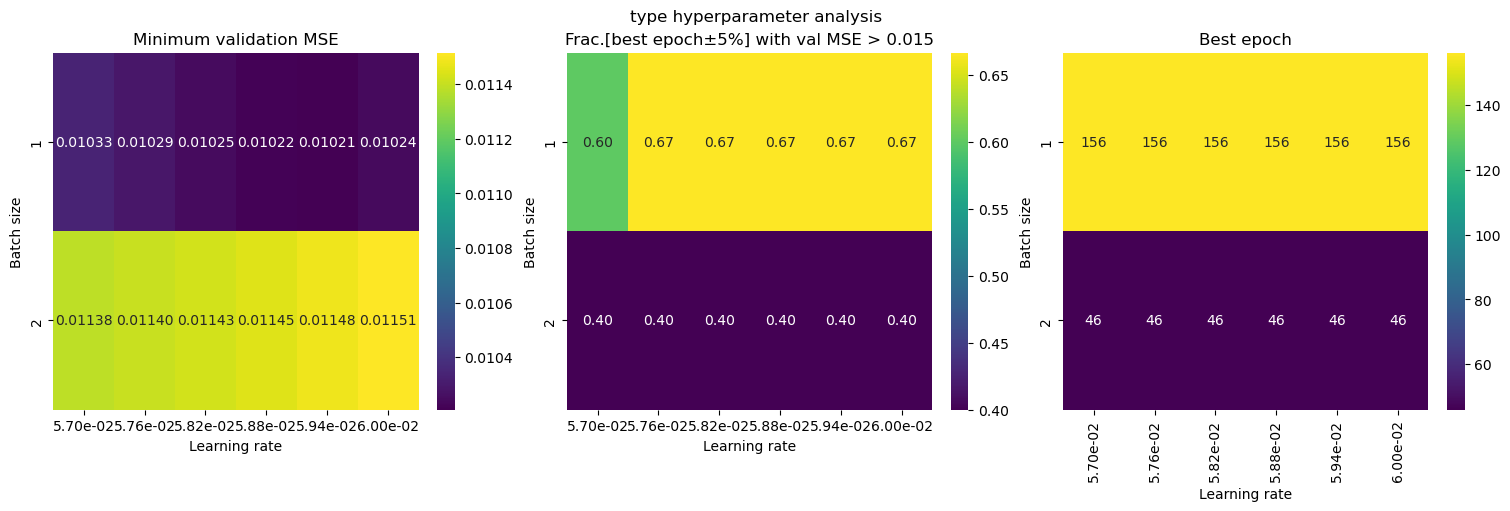

In [184]:
batch_sizes = [1, 2]
learning_rates = np.geomspace(5.7e-2, 6e-2, 6)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

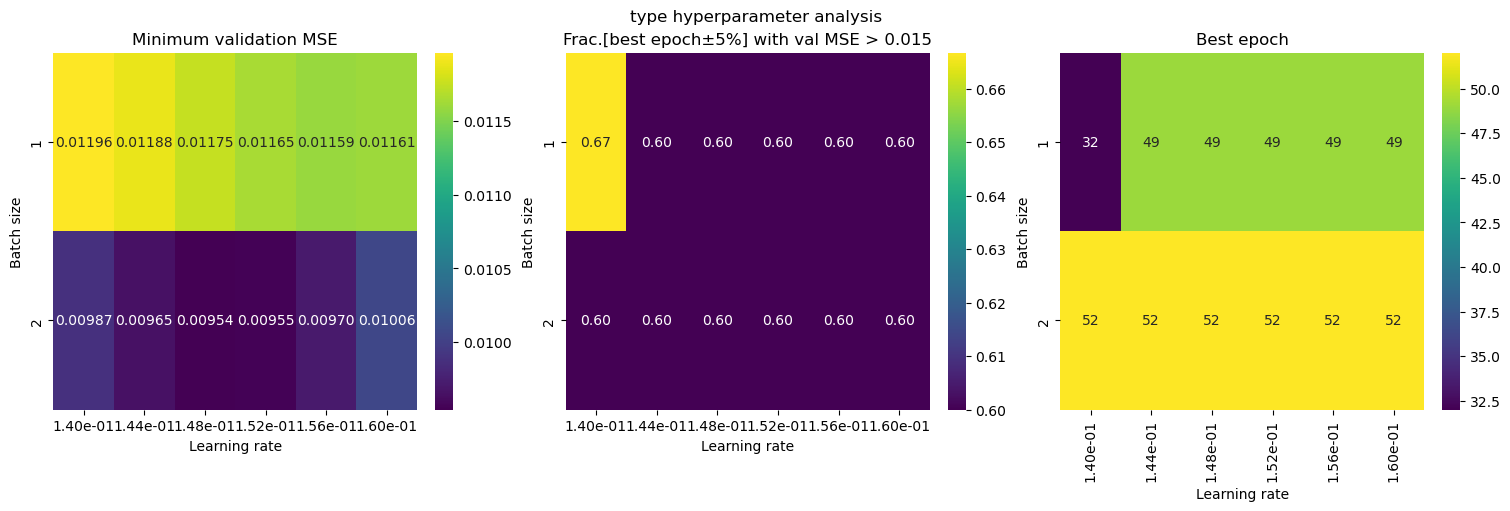

In [188]:
batch_sizes = [1, 2]
learning_rates = np.geomspace(1.4e-1, 1.6e-1, 6)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

I choose to use M=2 and gamma=1.5e-1 and epochs=52.

In [190]:
batch_size = 2
gamma = 1.5e-1
epochs = 52

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = Adam(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT Adam:")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT Adam:
M=2, gamma=0.15, epochs=52:
Test MSE: 0.01204


ALL RESULTS:

FINAL RESULT PLAIN GD:
M=1, gamma=0.0866, epochs=540:
Test MSE: 0.01287

FINAL RESULT RMSProp:
M=16, gamma=0.082, epochs=178:
Test MSE: 0.01278

FINAL RESULT Adam:
M=2, gamma=0.15, epochs=52:
Test MSE: 0.01204


Compared to OLS of Project 1:
Degree=8:
Test MSE: 0.01871

Repeat for two hidden layers. Hypothesis: mer processing power, men lavere MSE. 

In [1]:
layer_sizes = [1, 50, 100, 1]
activations = ["sigmoid", "sigmoid", "identity"]

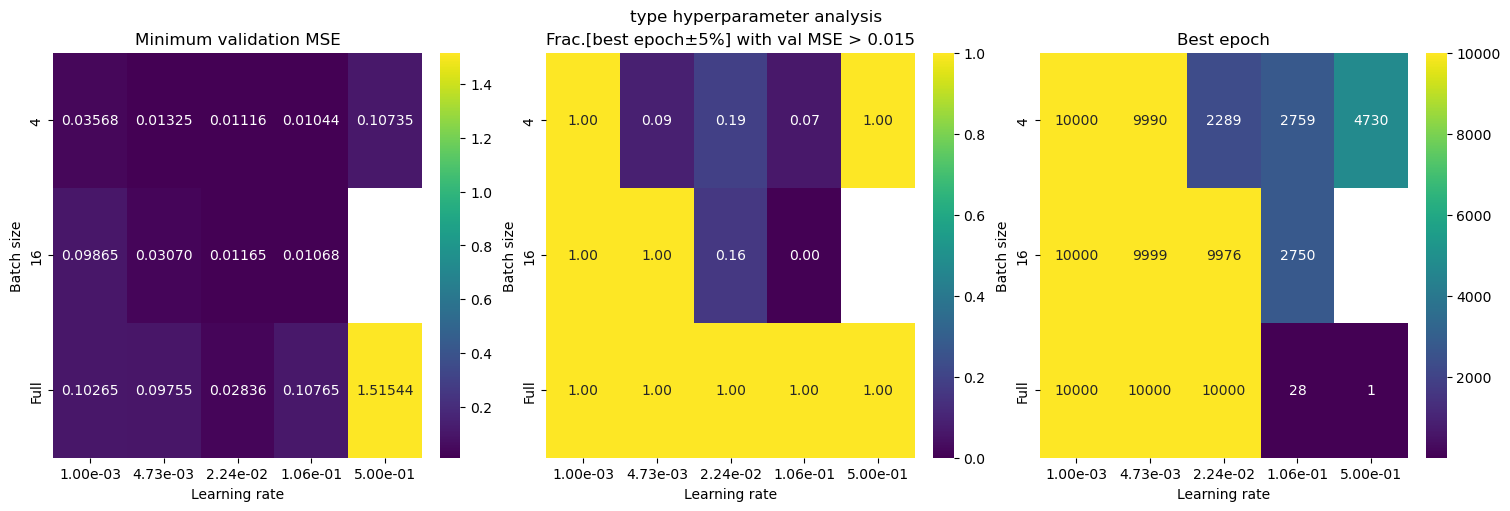

In [ ]:
epochs = 10000
optimizer_class = GD
batch_sizes = [4, 16, None]
learning_rates = np.geomspace(1e-3, 0.5, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

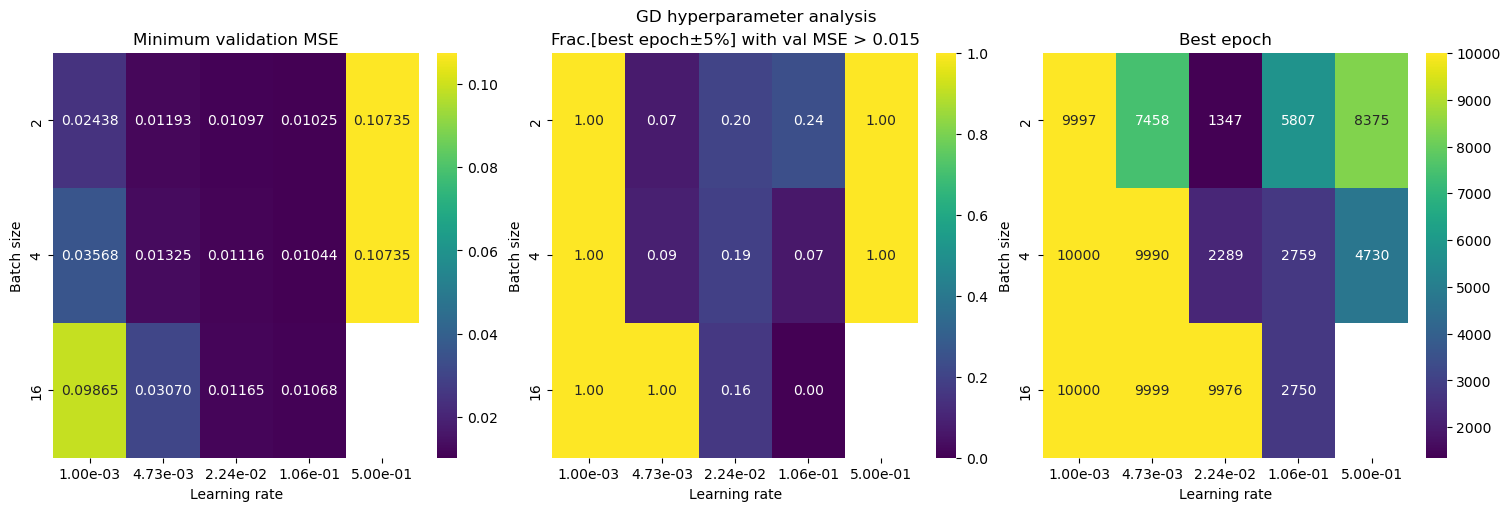

In [14]:
batch_sizes = [2, 4, 16]
learning_rates = np.geomspace(1e-3, 0.5, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting(optimizer_class, val_MSEs, fractions, best_epochs)

In [20]:
def hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates):
    fig, axs = plt.subplots(1, 3, figsize=(5 * 3, 5),
                        constrained_layout=True)

    batch_labels = [str(b) if b is not None else "Full" for b in batch_sizes]
    lr_labels = [f"{lr:.2e}" for lr in learning_rates]

    plot_heatmap(
        val_MSEs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Minimum validation MSE",
        fmt=".5f",
        ax=axs[0]
    )

    plot_heatmap(
        fractions,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Frac.[best epoch±5%] with val MSE > 0.015",
        fmt=".2f",
        ax=axs[1]
    )

    plot_heatmap(
        best_epochs,
        x_labels=lr_labels,
        y_labels=batch_labels,
        x_name="Learning rate",
        y_name="Batch size",
        title="Best epoch",
        fmt=".0f",
        ax=axs[2]
    )

    fig.suptitle(f"{optimizer_class.__name__} hyperparameter analysis. Layer sizes: {layer_sizes}. Activation functions: {activations}")
    plt.show()

M=1 is too computationally heavy for this neural network for plain gradient descent to reach low MSEs for different gammas. Hard to compare.  

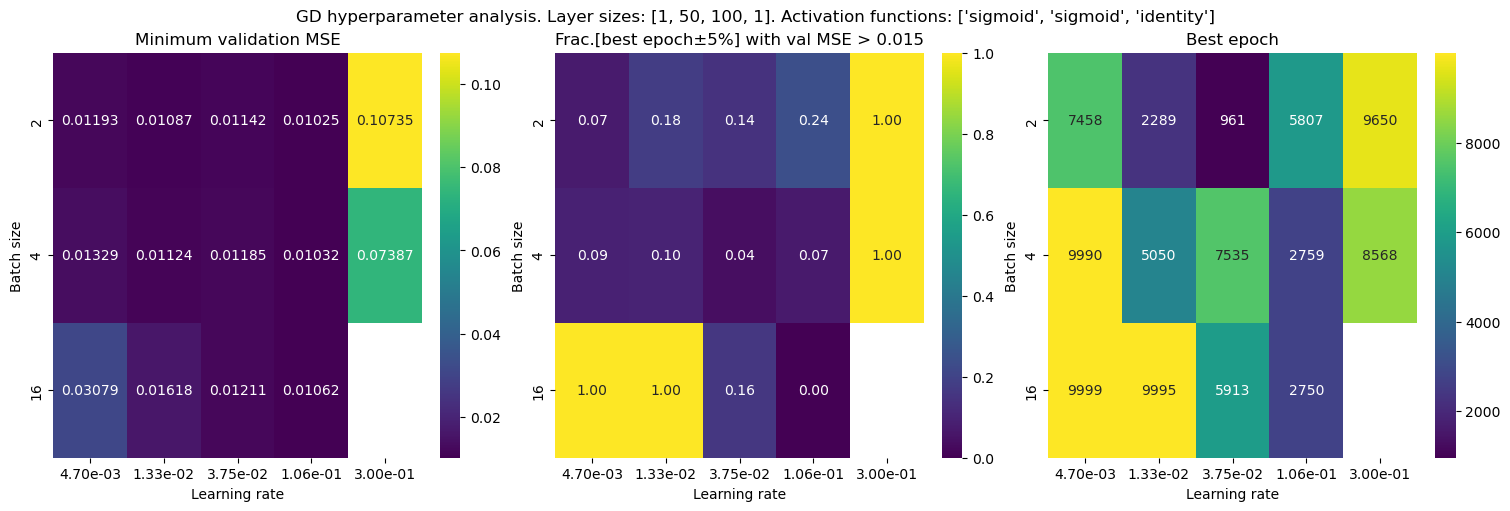

In [19]:
batch_sizes = [2, 4, 16]
learning_rates = np.geomspace(4.7e-3, 0.3, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs)

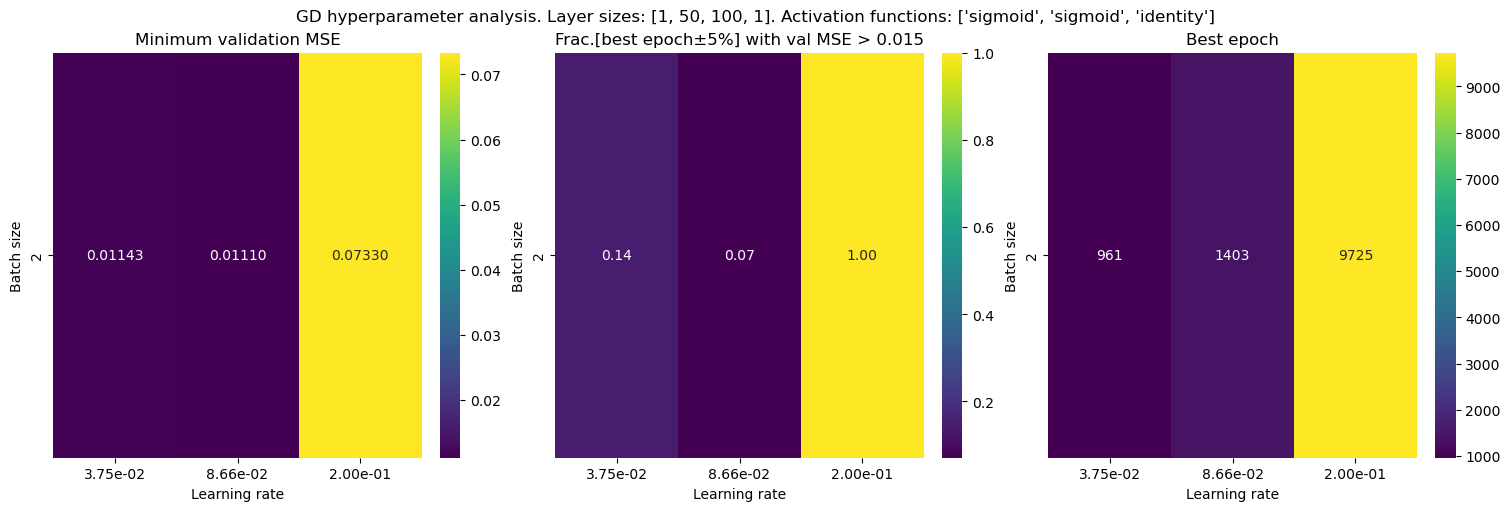

In [21]:
batch_sizes = [2]
learning_rates = np.geomspace(3.75e-2, 0.2, 3)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

Batch size = 2 også too computationally heavy. Sjekk bra område for M=4, 16. 

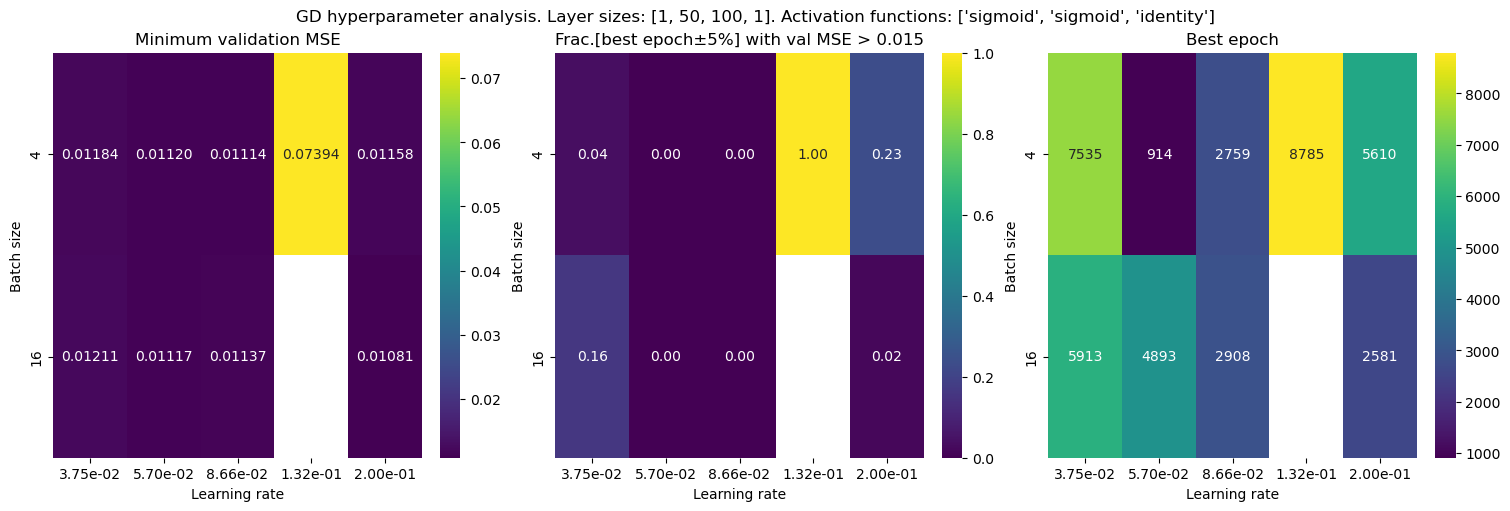

In [22]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(3.75e-2, 0.2, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

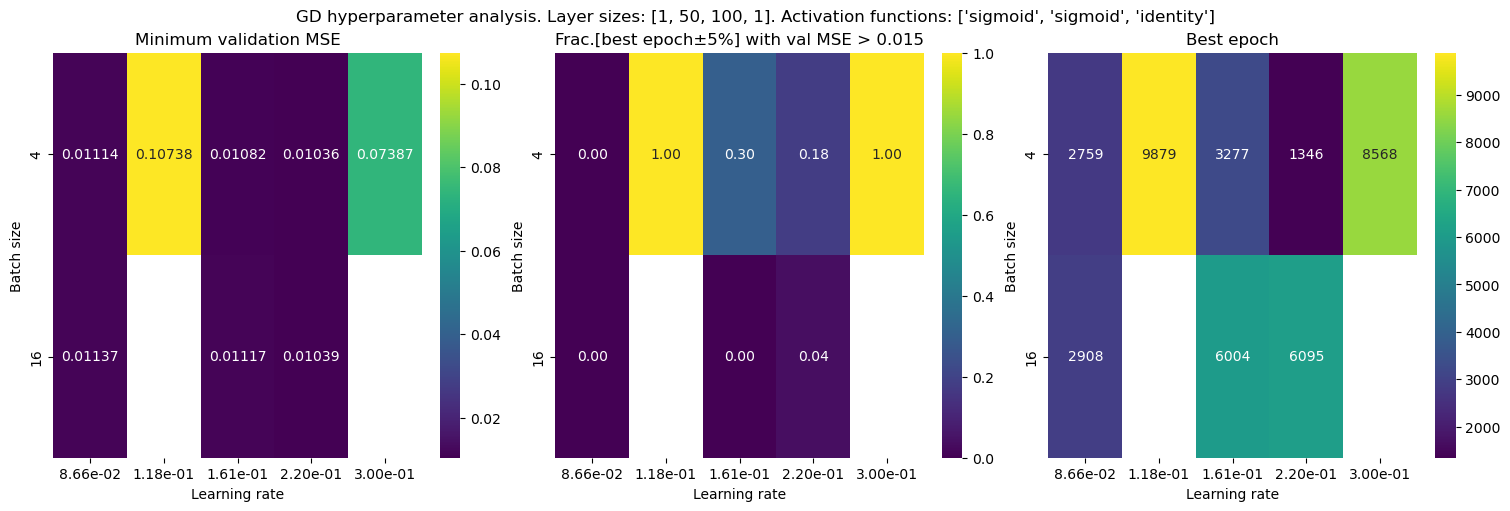

In [23]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(8.66e-2, 0.3, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

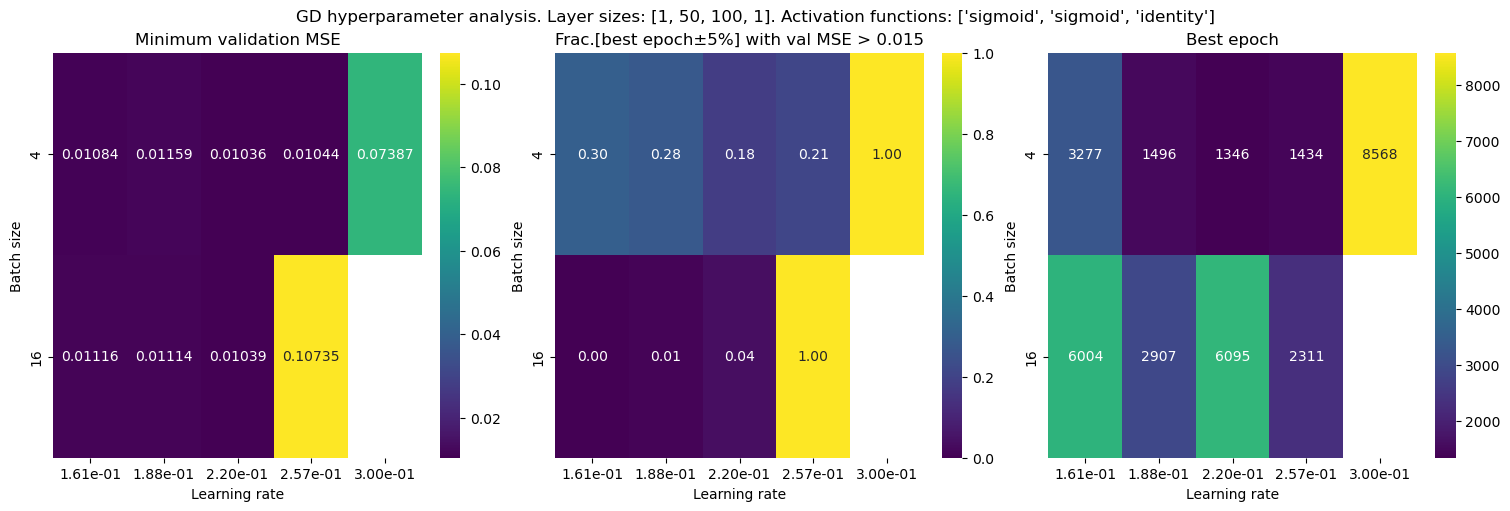

In [24]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(1.61e-1, 0.3, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

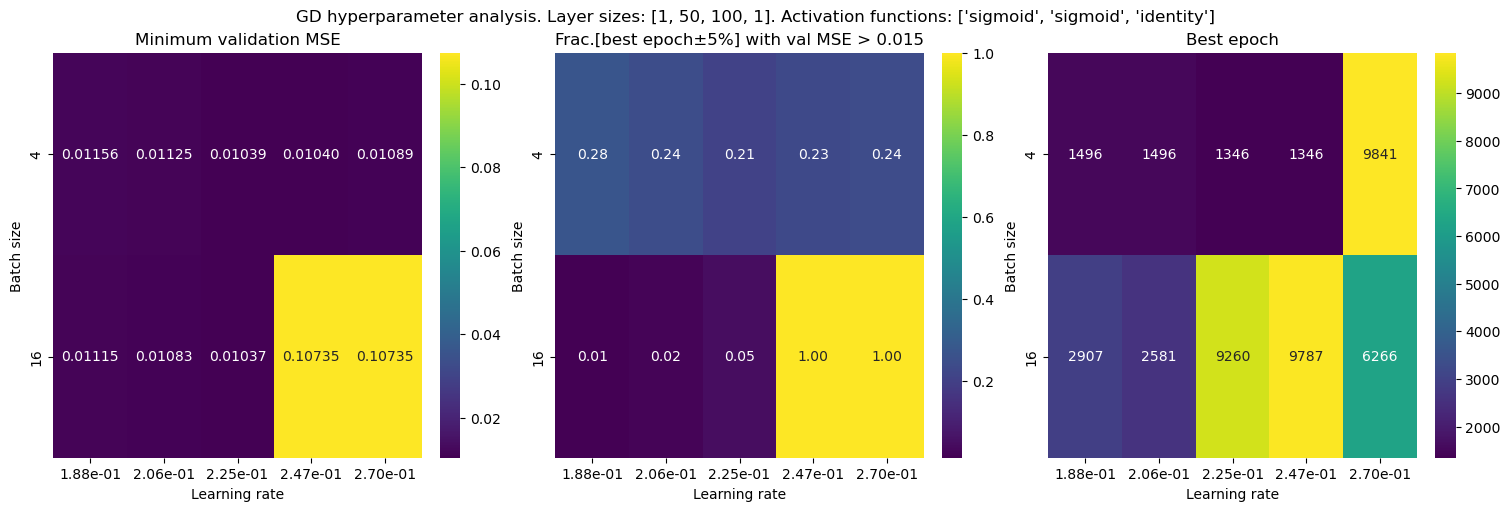

In [25]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(1.88e-1, 0.27, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

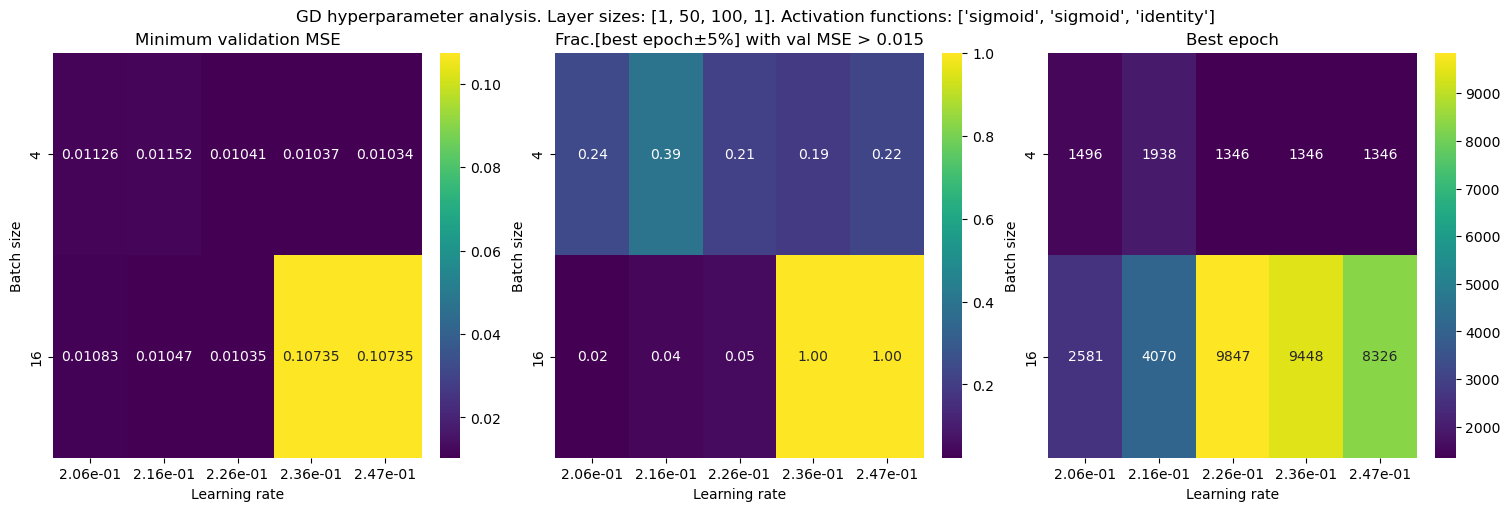

In [26]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(0.206, 0.247, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

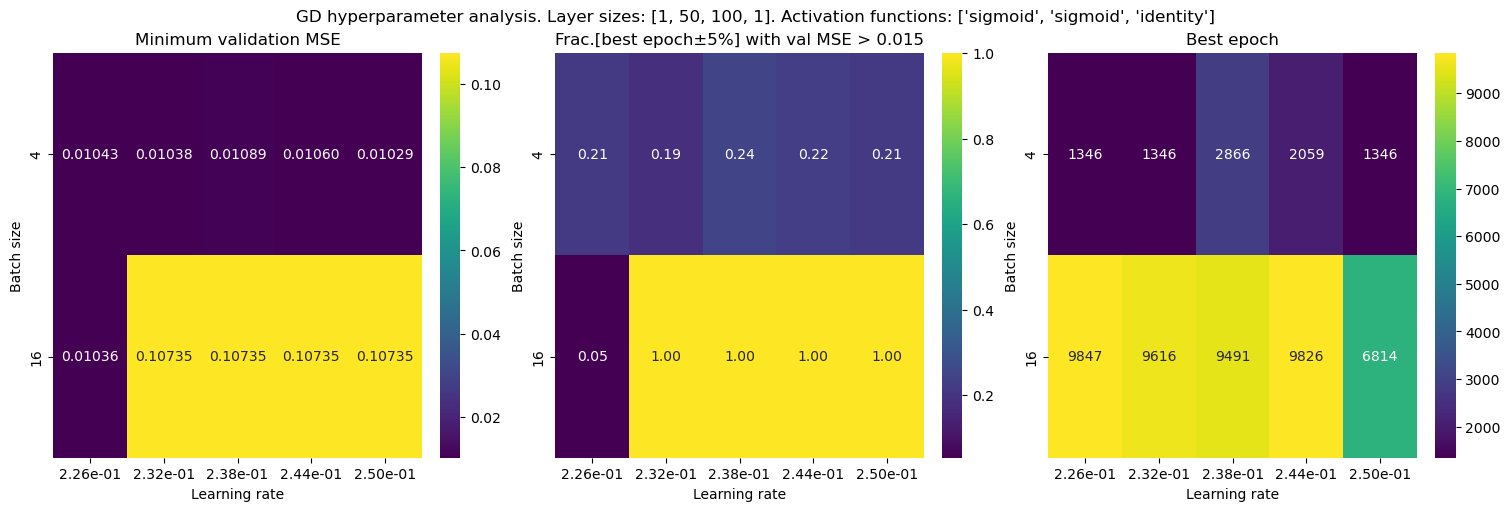

In [27]:
batch_sizes = [4, 16]
learning_rates = np.geomspace(0.226, 0.25, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

I choose M=4 , gamma=2.5, epochs=1346. men det var jo bedre den ene jeg fant med M=2, så gjør 1 sjekk med 5 forskjellige gamma rundt den som ga best. Så velg den. 

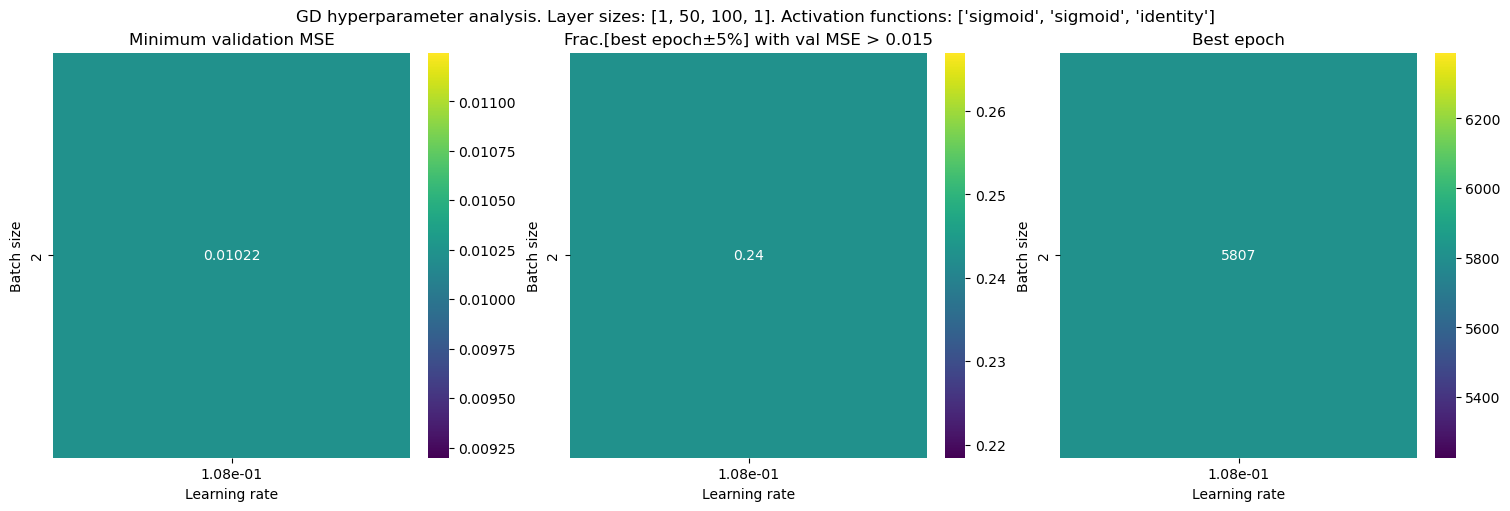

In [31]:
batch_sizes = [2]
learning_rates = [0.108]
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

In [32]:
batch_size = 2
gamma = 0.108
epochs = 5807

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT GD (2 layers):")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT GD (2 layers):
M=2, gamma=0.108, epochs=5807:
Test MSE: 0.01491


In [34]:
batch_size = 16
gamma = 0.226
epochs = 9847

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT GD (2 layers):")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT GD (2 layers):
M=16, gamma=0.226, epochs=9847:
Test MSE: 0.01189


In [35]:
batch_size = 16
gamma = 0.216
epochs = 4070

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = GD(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT GD (2 layers):")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT GD (2 layers):
M=16, gamma=0.216, epochs=4070:
Test MSE: 0.01208


I chose the one with the lowest val MSE but in this case that seems to have caused overfitting. Resultatene over er jo greie å ha med. Er vel lov å teste sånn på test? More complex model så gir mening. 

Gå videre til RMS.

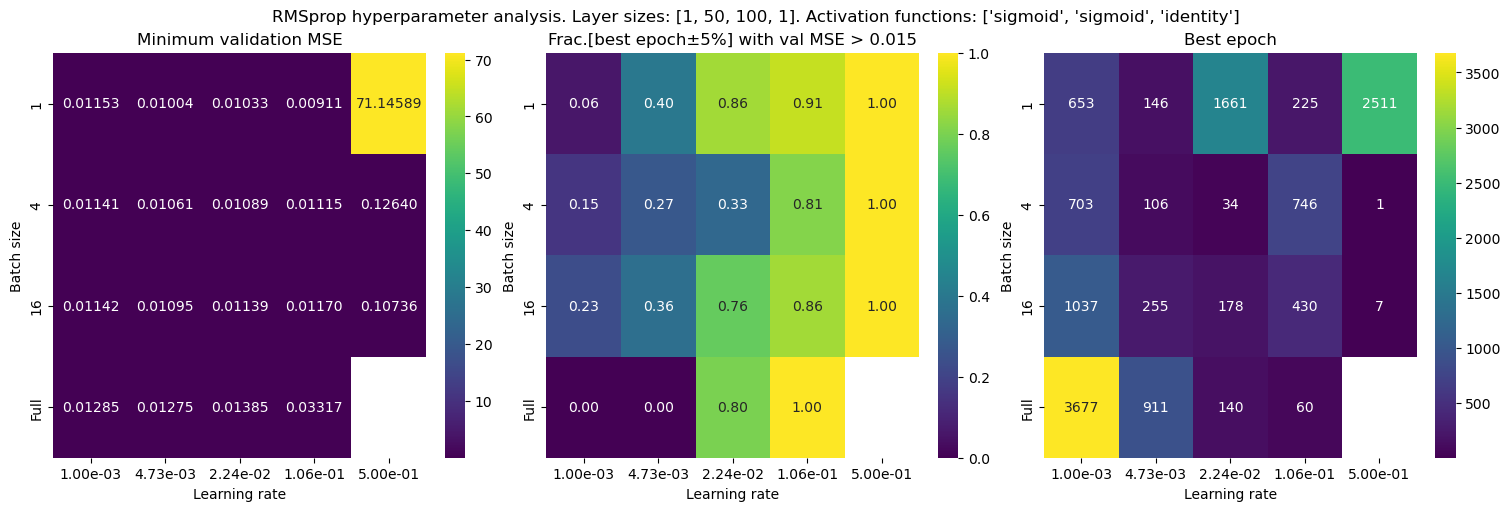

In [37]:
optimizer_class = RMSprop
batch_sizes = [1, 4, 16, None]
learning_rates = np.geomspace(1e-3, 0.5, 5)
val_MSEs, fractions, best_epochs = hyperpar_analysis(optimizer_class, batch_sizes, learning_rates)
hyperpar_plotting_new(layer_sizes, activations, optimizer_class, val_MSEs, fractions, best_epochs, batch_sizes, learning_rates)

Hvordan og hvorfor se på forskjellen mellom train og val MSE. hvordan minimere denne forskjellen?

Her er 16, 1e-3 mye mer stabil enn 1, 1.06e-1 og 2.24e-2. Sjekk test MSE for disse.

In [ ]:

batch_size = 16
gamma = 1e-3
epochs = 1037

nn_model = NeuralNetwork(layer_sizes, activations)
optimizer = RMSprop(gamma)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val, max_mse=1000.0)
test_error = nn_model.cost(X_test, y_test)
print("FINAL RESULT RMS (2 layers):")
print(f"M={batch_size}, gamma={gamma}, epochs={epochs}:")
print(f"Test MSE: {test_error:.5f}")

FINAL RESULT RMS (2 layers):
M=16, gamma=0.001, epochs=1037:
Test MSE: 0.01426
